# Actividad de Clustering y Reducción de Dimensión (**Aprendizaje No Supervisado**)

Ejercicios enfocados en:

1. **Marketing/Negocios** — K-Means (2D) con métricas internas y elección de *k*.
2. **Salud** — Comparación K-Means, GMM y DBSCAN (2D) con métricas internas (y externas opcionales).
3. **Jerárquico** + Dendrograma — *Wholesale Customers* (UCI).
4. **Reducción de Dimensión (PCA)** y comparación 2D entre **pares de características** vs **PC1–PC2**.

> Ejecuta las celdas en orden. Evita cambiar manualmente rutas; todo se carga desde URLs públicas.


## 0) Configuración de entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, dendrogram

np.random.seed(42)
print("Entorno listo.")


Entorno listo.



## **Ejercicio 1** — K-Means (2 características) para segmentación de clientes

**Dataset:** *Mall Customers* (URL):  
`https://www.dmi.unict.it/ortis/StatsLab/2022-2023/Notebooks/Statistical%20Laboratory%20-%20Mall%20Customers.html`

**Objetivo:** visualizar cómo cambian los grupos al variar **k** y medir la calidad de la segmentación.  
**Features (2D):** `Annual Income (k$)` y `Spending Score (1-100)`.

**Métricas internas:** **Silhouette (↑)**, **Codo/SSE (↓)**, **Davies–Bouldin (↓)**, **Calinski–Harabasz (↑)**.


- Analiza diferentes clusters que se presentan al utilizar solo dos características, y cuales métricas de desempeño en la selección del número de clusters se puede utilizar.

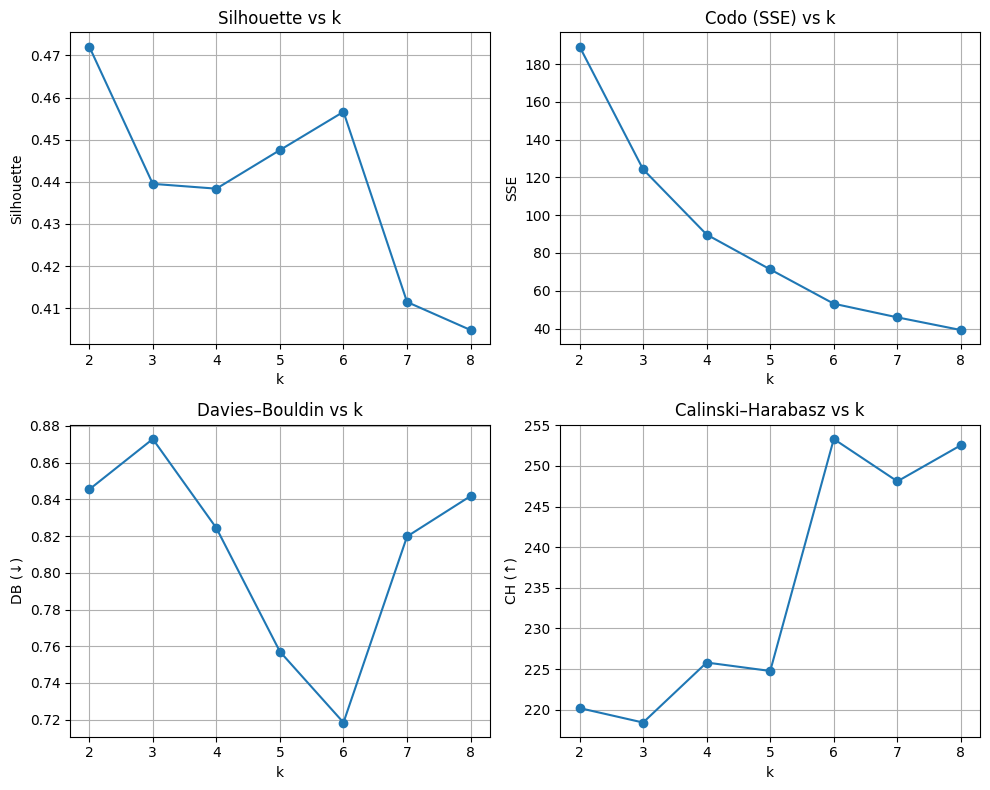

In [2]:
# Cargar el conjunto de datos
mall_url = "https://assets.datacamp.com/production/repositories/5838/datasets/083224d85bfe51f091d9641fbfc95e60ba95c0ba/Mall_Customers.csv"
mall = pd.read_csv(mall_url)

# Selecciona 2 de las características del conjunto
feat_x, feat_y = "Age", "Spending Score (1-100)"
X2 = mall[[feat_x, feat_y]].dropna().values

# Realiza una Estandarización de los datos para reducir la influencia de la escala de los datos
scaler = StandardScaler()
X2s = scaler.fit_transform(X2)


ks = list(range(2, 9))
sil_scores, inertias, db_scores, ch_scores = [], [], [], []

# Calculo iterativo cambiando el número esperado de clusters para evaluar 4 métricas de desempeño
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42) # Modelo de K-Means
    labels = km.fit_predict(X2s)
    sil_scores.append(silhouette_score(X2s, labels)) #Silhouette
    inertias.append(km.inertia_) # Codo (SSE)
    db_scores.append(davies_bouldin_score(X2s, labels)) # Davies-Bouldin
    ch_scores.append(calinski_harabasz_score(X2s, labels)) # Calinski-Harabaz

# Visualización de métricas en 2x2
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].plot(ks, sil_scores, marker='o'); axes[0, 0].set_title("Silhouette vs k"); axes[0, 0].set_xlabel("k"); axes[0, 0].set_ylabel("Silhouette"); axes[0, 0].grid(True)
axes[0, 1].plot(ks, inertias, marker='o'); axes[0, 1].set_title("Codo (SSE) vs k"); axes[0, 1].set_xlabel("k"); axes[0, 1].set_ylabel("SSE"); axes[0, 1].grid(True)
axes[1, 0].plot(ks, db_scores, marker='o'); axes[1, 0].set_title("Davies–Bouldin vs k"); axes[1, 0].set_xlabel("k"); axes[1, 0].set_ylabel("DB (↓)"); axes[1, 0].grid(True)
axes[1, 1].plot(ks, ch_scores, marker='o'); axes[1, 1].set_title("Calinski–Harabasz vs k"); axes[1, 1].set_xlabel("k"); axes[1, 1].set_ylabel("CH (↑)"); axes[1, 1].grid(True)
plt.tight_layout(); plt.show()

- Fija un valor de k y analiza los resultados.

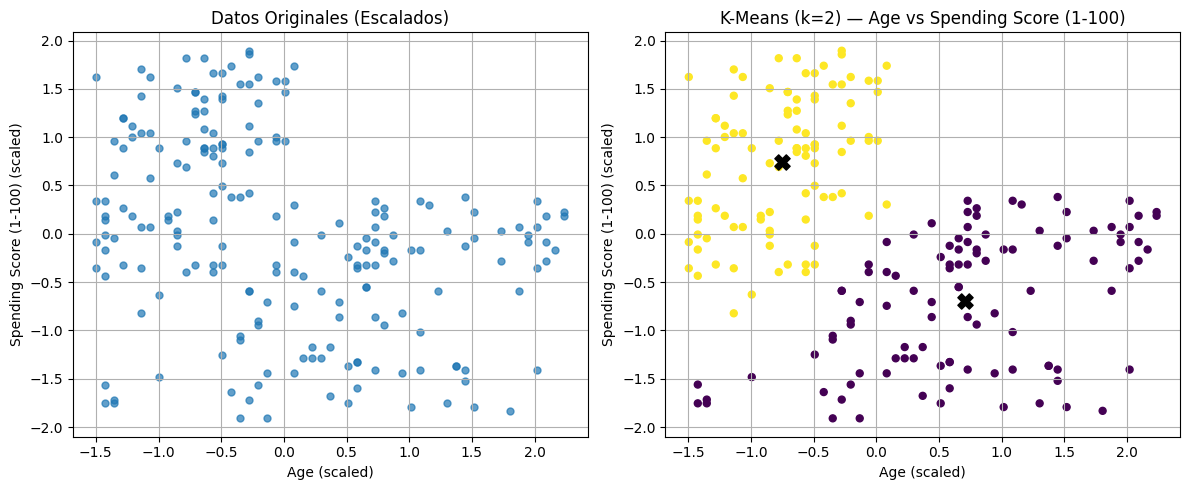

Silhouette: 0.4721271643062346
Davies–Bouldin: 0.8454075317907336
Calinski–Harabasz: 220.19023979802992


In [3]:
k_chosen = 2
km = KMeans(n_clusters=k_chosen, n_init=10, random_state=42)
labels = km.fit_predict(X2s)
centroids = km.cluster_centers_

# Visualización comparativa 1x2: antes y después de clustering
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter plot antes de clustering
axes[0].scatter(X2s[:,0], X2s[:,1], s=25, alpha=0.7)
axes[0].set_title("Datos Originales (Escalados)"); axes[0].set_xlabel(feat_x + " (scaled)"); axes[0].set_ylabel(feat_y + " (scaled)"); axes[0].grid(True)

# Scatter plot después de clustering
axes[1].scatter(X2s[:,0], X2s[:,1], c=labels, s=25)
axes[1].scatter(centroids[:,0], centroids[:,1], marker='X', s=120, color='black')
axes[1].set_title(f"K-Means (k={k_chosen}) — {feat_x} vs {feat_y}"); axes[1].set_xlabel(feat_x + " (scaled)"); axes[1].set_ylabel(feat_y + " (scaled)"); axes[1].grid(True)

plt.tight_layout(); plt.show()


print("Silhouette:", silhouette_score(X2s, labels))
print("Davies–Bouldin:", davies_bouldin_score(X2s, labels))
print("Calinski–Harabasz:", calinski_harabasz_score(X2s, labels))

### Actividades:

1. Cambia una de las características utilizadas para el análisis, conservando la variable objetivo que para este caso es `Spending Score (1-100)`
2. Observa los cuatro gráficos de métricas. ¿Qué valor de **k** sugieren las métricas de Silhouette, Davies–Bouldin y Calinski–Harabasz como el óptimo? ¿Y la métrica del Codo?
2.  Con base en los gráficos de métricas y tu intuición sobre la forma de los datos en el scatter plot de K-Means, justifica por qué se eligió `k=5` en la celda anterior.
3.  Interpreta los cinco segmentos identificados por K-Means. Describe brevemente a cada grupo de clientes (p. ej., "Clientes de alto ingreso y alto gasto"). Puedes basarte en la posición de los centroides en el scatter plot.
4.  (Opcional) Intenta cambiar el valor de `k_chosen` en la celda de código y ejecuta solo esa celda. Observa cómo cambia la visualización y las métricas finales. ¿Te parece que otro valor de k podría ser mejor? ¿Por qué?

## Respuestas Ejercicio 1

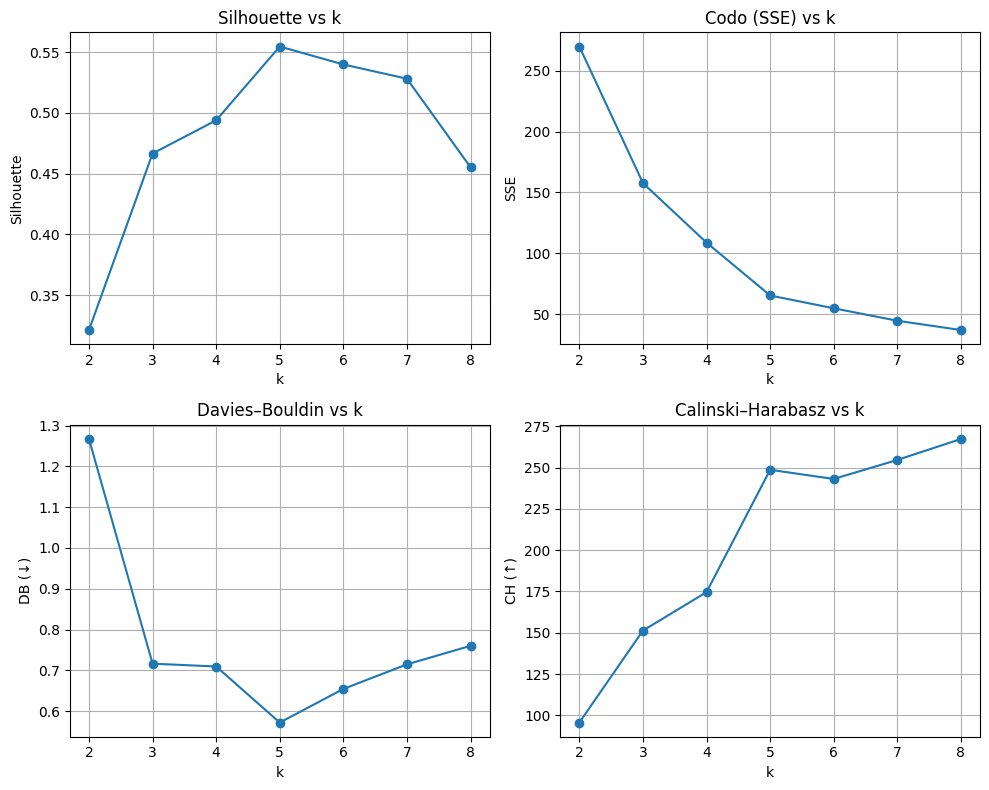

In [4]:
# 1. Cambiar una de las características

mall.describe()

# De la información del dataframe, escogemos Annual Income (k$)

feat_x, feat_y = "Annual Income (k$)", "Spending Score (1-100)"
X2 = mall[[feat_x, feat_y]].dropna().values

# Realiza una Estandarización de los datos para reducir la influencia de la escala de los datos
scaler = StandardScaler()
X2s = scaler.fit_transform(X2)


ks = list(range(2, 9))
sil_scores, inertias, db_scores, ch_scores = [], [], [], []

# Calculo iterativo cambiando el número esperado de clusters para evaluar 4 métricas de desempeño
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42) # Modelo de K-Means
    labels = km.fit_predict(X2s)
    sil_scores.append(silhouette_score(X2s, labels)) #Silhouette
    inertias.append(km.inertia_) # Codo (SSE)
    db_scores.append(davies_bouldin_score(X2s, labels)) # Davies-Bouldin
    ch_scores.append(calinski_harabasz_score(X2s, labels)) # Calinski-Harabaz

# Visualización de métricas en 2x2
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].plot(ks, sil_scores, marker='o'); axes[0, 0].set_title("Silhouette vs k"); axes[0, 0].set_xlabel("k"); axes[0, 0].set_ylabel("Silhouette"); axes[0, 0].grid(True)
axes[0, 1].plot(ks, inertias, marker='o'); axes[0, 1].set_title("Codo (SSE) vs k"); axes[0, 1].set_xlabel("k"); axes[0, 1].set_ylabel("SSE"); axes[0, 1].grid(True)
axes[1, 0].plot(ks, db_scores, marker='o'); axes[1, 0].set_title("Davies–Bouldin vs k"); axes[1, 0].set_xlabel("k"); axes[1, 0].set_ylabel("DB (↓)"); axes[1, 0].grid(True)
axes[1, 1].plot(ks, ch_scores, marker='o'); axes[1, 1].set_title("Calinski–Harabasz vs k"); axes[1, 1].set_xlabel("k"); axes[1, 1].set_ylabel("CH (↑)"); axes[1, 1].grid(True)
plt.tight_layout(); plt.show()

2. Las gráficas de las métricas anteriores sugieren:

*   **Silhouette:** La puntuación Silhouette es mejor cuanto más se acerca a 1. Observando el gráfico "Silhouette vs k", el valor más alto se alcanza en k=5.
*   **Codo (SSE):** Buscamos el "codo" en el gráfico "Codo (SSE) vs k". La mayor disminución en la inercia ocurre entre k=2 y k=3, y la curva comienza a aplanarse después de k=5. Esto sugiere que k=5 podría ser un punto de inflexión razonable, aunque el "codo" no es tan pronunciado.
*   **Davies–Bouldin:** Esta métrica debe minimizarse. En el gráfico "Davies–Bouldin vs k", el valor más bajo se observa en k=5.
*   **Calinski–Harabasz:** Esta métrica debe maximizarse. En el gráfico "Calinski–Harabasz vs k", el valor más alto se alcanza en k=8.

En resumen, las métricas Silhouette, Davies–Bouldin sugieren consistentemente que **k=5** es el número óptimo de clusters para este conjunto de datos con las características 'Annual Income (k$)' y 'Spending Score (1-100)'. La métrica del Codo también parece respaldar esta elección como un punto donde la mejora en la inercia comienza a disminuir.

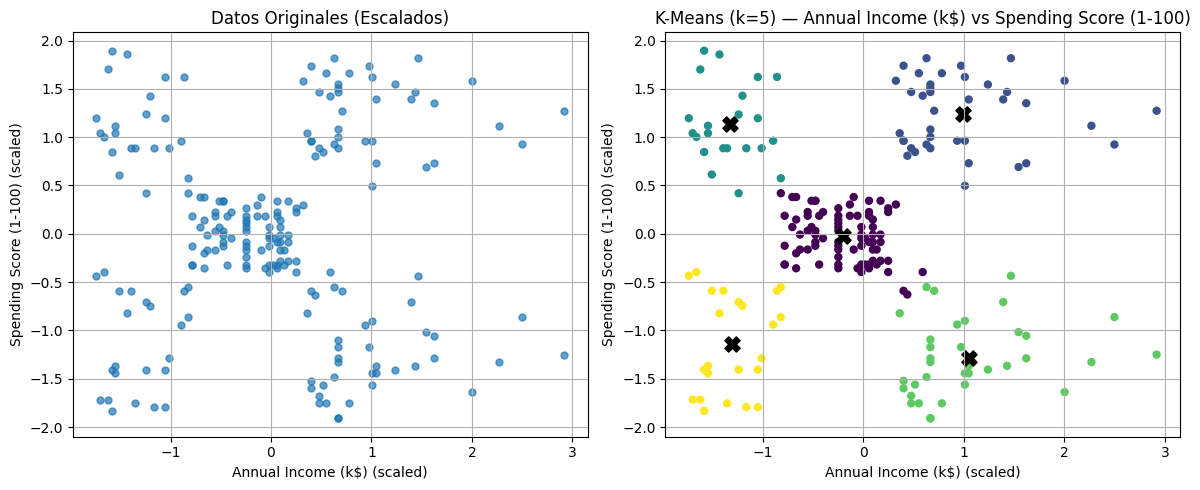

Silhouette: 0.5546571631111091
Davies–Bouldin: 0.5722356162263352
Calinski–Harabasz: 248.64932001536357


In [5]:
k_chosen = 5
km = KMeans(n_clusters=k_chosen, n_init=10, random_state=42)
labels = km.fit_predict(X2s)
centroids = km.cluster_centers_

# Visualización comparativa 1x2: antes y después de clustering
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter plot antes de clustering
axes[0].scatter(X2s[:,0], X2s[:,1], s=25, alpha=0.7)
axes[0].set_title("Datos Originales (Escalados)"); axes[0].set_xlabel(feat_x + " (scaled)"); axes[0].set_ylabel(feat_y + " (scaled)"); axes[0].grid(True)

# Scatter plot después de clustering
axes[1].scatter(X2s[:,0], X2s[:,1], c=labels, s=25)
axes[1].scatter(centroids[:,0], centroids[:,1], marker='X', s=120, color='black')
axes[1].set_title(f"K-Means (k={k_chosen}) — {feat_x} vs {feat_y}"); axes[1].set_xlabel(feat_x + " (scaled)"); axes[1].set_ylabel(feat_y + " (scaled)"); axes[1].grid(True)

plt.tight_layout(); plt.show()


print("Silhouette:", silhouette_score(X2s, labels))
print("Davies–Bouldin:", davies_bouldin_score(X2s, labels))
print("Calinski–Harabasz:", calinski_harabasz_score(X2s, labels))

3. Con base en los gráficos de métricas y la forma de los datos en el scatter plot, se eligió **k=5** por las siguientes razones:

*   **Consistencia de Métricas:** Como se analizó en la respuesta anterior, las métricas Silhouette, Davies–Bouldin alcanzaron sus valores óptimos o cercanos a ellos en k=5. Esto proporciona un fuerte respaldo numérico para esta elección.
*   **Método del Codo:** Aunque el "codo" en el gráfico de inercia no es extremadamente pronunciado, el punto en k=5 parece ser donde la tasa de disminución de la inercia comienza a estabilizarse, sugiriendo que agregar más clusters más allá de 5 no ofrece una mejora sustancial en la reducción de la suma de cuadrados dentro de los clusters.
*   **Intuición Visual en el Scatter Plot:** Al observar el scatter plot de los datos con las características 'Annual Income (k$)' y 'Spending Score (1-100)', se pueden identificar visualmente agrupaciones de puntos que parecen sugerir la presencia de alrededor de 5 clusters distintos. Hay grupos claros en las esquinas (bajo ingreso/bajo gasto, alto ingreso/alto gasto) y un grupo central, además de posibles grupos de alto ingreso/bajo gasto y bajo ingreso/alto gasto. El valor de k=5 parece corresponder bien con esta estructura visual aparente en los datos.

Considerando la combinación de la evidencia numérica de las métricas y la estructura visual de los datos, k=5 emerge como una elección razonable y bien justificada para el número de clusters en este caso.

4. Basándonos en la posición de los centroides en el scatter plot para k=5 (mostrado en la celda `2j-DLl258Jy6`), podemos interpretar los cinco segmentos de clientes de la siguiente manera:

*   **Segmento 0 (Alto Ingreso, Bajo Gasto):** Clientes con altos ingresos anuales pero puntuaciones de gasto bajas. Podrían ser clientes ahorradores.
*   **Segmento 1 (Ingreso Promedio, Gasto Promedio):** Este es un grupo central de clientes con ingresos y puntuaciones de gasto moderados. Puede ser la media de la población de clientes
*   **Segmento 2 (Bajo Ingreso, Bajo Gasto):** Clientes con bajos ingresos anuales y bajas puntuaciones de gasto. Podrían ser clientes con presupuestos limitados o compradores con poca frecuencia.
*   **Segmento 3 (Bajo Ingreso, Alto Gasto):** Clientes con bajos ingresos pero altas puntuaciones de gasto. Este grupo podría ser interesante pues gastan significativamente a pesar de tener ingresos bajos.
*   **Segmento 4 (Alto Ingreso, Alto Gasto):** Clientes con altos ingresos anuales y altas puntuaciones de gasto. Son los clientes de mayor gasto y que pueden ser los más valiosos para retener


## **Ejercicio 2** — Comparación K-Means vs GMM vs DBSCAN (2 características)

**Dataset:** *Heart Disease* (URL):  
`https://archive.ics.uci.edu/dataset/45/heart+disease`

**Features (2D):** elige dos entre `age`, `chol`, `trestbps`, `thalach`.  
**Métrica interna:** **Silhouette** (manejar ruido en DBSCAN).  

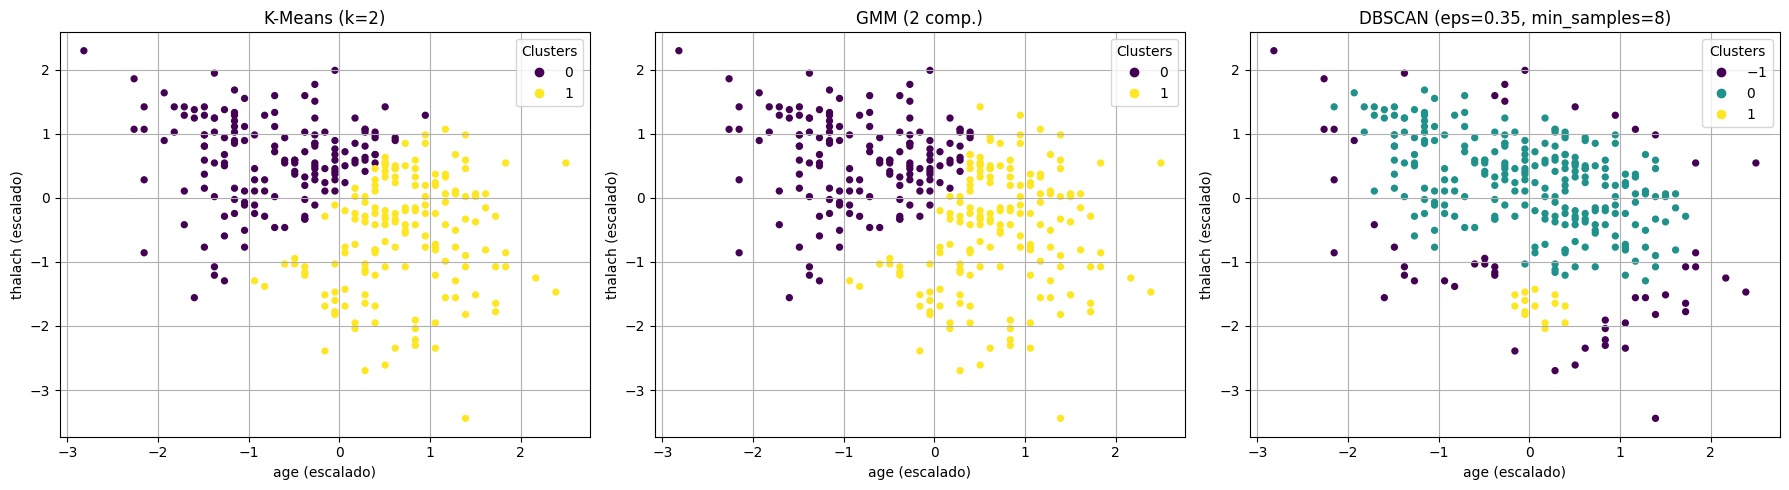

Silhouette K-Means: 0.3865807185420207
Silhouette GMM:    0.3828305256946685
Silhouette DBSCAN: 0.3275657137240824


In [6]:
# Importar librerías necesarias para métricas externas (opcional)
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

# Cargar el conjunto de datos Heart Disease desde la URL de UCI
heart_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
# Definir los nombres de las columnas ya que el dataset original no tiene encabezado
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
heart = pd.read_csv(heart_url, names=column_names, na_values='?')

# Seleccionar dos características y eliminar filas con valores faltantes
feat1, feat2 = "age", "thalach"
Xh2 = heart[[feat1, feat2]].dropna().values

# Estandarizar los datos
Xh2s = StandardScaler().fit_transform(Xh2)

# --- K-Means ---
# Inicializar y ajustar el modelo K-Means con k=2
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xh2s)
# Obtener las etiquetas de los clusters
labels_km = km.labels_

# --- GMM ---
# Inicializar y ajustar el modelo Gaussian Mixture Model (GMM) con 2 componentes
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42).fit(Xh2s)
# Predecir las etiquetas de los clusters
labels_gmm = gmm.predict(Xh2s)

# --- DBSCAN ---
# Inicializar y ajustar el modelo DBSCAN
db = DBSCAN(eps=0.35, min_samples=8).fit(Xh2s)
# Obtener las etiquetas de los clusters (-1 indica ruido)
labels_db = db.labels_

# --- Visualización comparativa en un arreglo 1x3 ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graficar resultados de K-Means
scatter_km = axes[0].scatter(Xh2s[:, 0], Xh2s[:, 1], c=labels_km, s=18)
axes[0].set_title("K-Means (k=2)")
axes[0].set_xlabel(feat1 + " (escalado)"); axes[0].set_ylabel(feat2 + " (escalado)"); axes[0].grid(True)
axes[0].legend(*scatter_km.legend_elements(), title="Clusters")

# Graficar resultados de GMM
scatter_gmm = axes[1].scatter(Xh2s[:, 0], Xh2s[:, 1], c=labels_gmm, s=18)
axes[1].set_title("GMM (2 comp.)")
axes[1].set_xlabel(feat1 + " (escalado)"); axes[1].set_ylabel(feat2 + " (escalado)"); axes[1].grid(True)
axes[1].legend(*scatter_gmm.legend_elements(), title="Clusters")

# Graficar resultados de DBSCAN
scatter_db = axes[2].scatter(Xh2s[:, 0], Xh2s[:, 1], c=labels_db, s=18)
axes[2].set_title("DBSCAN (eps=0.35, min_samples=8)")
axes[2].set_xlabel(feat1 + " (escalado)"); axes[2].set_ylabel(feat2 + " (escalado)"); axes[2].grid(True)
axes[2].legend(*scatter_db.legend_elements(), title="Clusters")

# Ajustar diseño y mostrar gráficos
plt.tight_layout()
plt.show()

# --- Cálculo de métricas internas (Silhouette) ---
# Función auxiliar para calcular Silhouette de forma segura (manejar ruido en DBSCAN)
def safe_silhouette(X, labels):
    valid = labels >= 0
    uniq = np.unique(labels[valid])
    if len(uniq) >= 2:
        return silhouette_score(X[valid], labels[valid])
    return np.nan

# Imprimir puntuaciones Silhouette para cada modelo
print("Silhouette K-Means:", silhouette_score(Xh2s, labels_km))
print("Silhouette GMM:   ", silhouette_score(Xh2s, labels_gmm))
print("Silhouette DBSCAN:", safe_silhouette(Xh2s, labels_db))

### Actividades (Ejercicio 2):

1.  **Análisis Visual:** Observa los tres scatter plots que muestran los resultados de K-Means, GMM y DBSCAN. ¿Cómo se comparan visualmente los clusters identificados por cada algoritmo? ¿Qué diferencias notas en la forma, tamaño y número de clusters (incluyendo el ruido en DBSCAN)?
2.  **Análisis de Métricas Internas (Silhouette):** Compara las puntuaciones Silhouette obtenidas por cada algoritmo. ¿Qué nos dice la puntuación Silhouette sobre la calidad de los clusters para cada modelo? ¿Hay alguna limitación al usar Silhouette con DBSCAN debido a los puntos de ruido?
3.  **Interpretación de Resultados:** Basándote en la visualización y la métrica Silhouette, ¿cuál de los tres algoritmos parece haber encontrado una estructura de clustering más "razonable" en este dataset bidimensional (age vs thalach)? Justifica tu respuesta.
4.  **Experimentación con Parámetros:** Intenta cambiar los parámetros de los algoritmos:
    *   Para K-Means y GMM, experimenta con `n_clusters` (p. ej., 3 o 4).
    *   Para DBSCAN, prueba diferentes valores de `eps` y `min_samples`.
    *   Ejecuta la celda modificada y observa cómo cambian las visualizaciones y las métricas. ¿Encuentras alguna configuración de parámetros que mejore significativamente los resultados según las métricas internas?
5. **Análisis con Métricas Externas (ARI):** Si la columna `target` está disponible y la consideras una "verdad fundamental" (aunque los clusters no necesariamente se alineen perfectamente con ella), analiza las puntuaciones ARI. ¿Qué te dicen estas métricas sobre cuán bien se alinean los clusters encontrados con la variable objetivo? ¿Por qué ARI podría ser una métrica relevante aquí (o no)?
6. Analiza el conjunto de características y selecciona dos que mejoren el proceso de agrupamiento. Elabora una tabla comparativa entre los pares de características, los tres métodos evaluados y el indice ARI y Silhouette, para sustentar el análisis.

## Respuestas Ejercicio 2

1. Visualmente, se uede ver que K-Means y GMM dividen los datos en dos grupos bien definidos, con K-Means generando una frontera más recta. DBSCAN por otra parte no parece lograr agrupar bien los datos con los parámetros configurados, dejando un gran grupo central, un pequeño grupo en la parte inferior del plot y varios outliers que no pudo agrupar claramente.

2. Análisis de Métricas Internas (Silhouette):

* **K-Means (Silhouette: 0.3866):** La puntuación Silhouette para K-Means (con k=2) es moderada. Un valor cercano a 0.4 sugiere que los clusters están algo separados, pero no hay una separación muy clara. Los puntos no están particularmente cerca del centroide de su propio cluster en comparación con los centroides de otros clusters. Esto concuerda con la visualización, donde los dos clusters de K-Means tienen cierta superposición.
* **GMM (Silhouette: 0.3828):** La puntuación Silhouette para GMM (con 2 componentes) es muy similar a la de K-Means, ligeramente inferior. Esto indica una calidad de agrupación comparable a K-Means para esta configuración y métrica. Visualmente, GMM también produce dos clusters que no están perfectamente separados.
* **DBSCAN (Silhouette: 0.3276):** La puntuación Silhouette para DBSCAN (con los parámetros elegidos) es la más baja de los tres. Esto sugiere que, según esta métrica, los clusters identificados por DBSCAN no están tan bien definidos o separados como los de K-Means y GMM.

**Limitaciones de Silhouette con DBSCAN:**
Sí, hay una limitación importante. Al analizar la gráfica, vemos que DBSCAN no tuvo un buen desempeño dado que dejó varios puntos como outliers para la configuración dada, pero su métrica Silhouette es tan alta como los otros dos métodos.

Una rápida búsqueda en [Google](https://medium.com/biased-algorithms/silhouette-score-d85235e7638b) sugiere que la métrica intenta dar una interpretación a la "compactación" del cluster y su "separación" de otros clústeres.  La métrica Silhouette se calcula para puntos que pertenecen a un cluster. Los puntos identificados como "ruido" por DBSCAN (etiqueta -1) no se incluyen en el cálculo estándar de la puntuación Silhouette. Si una gran proporción de puntos se clasifica como ruido, la puntuación Silhouette solo reflejará la calidad de los clusters formados por los puntos no ruidosos, lo que puede dar una imagen incompleta del rendimiento general del algoritmo en el dataset. Entonces, el resultado debe interpretarse con precaución, sabiendo que no evalúa cómo se relacionan los puntos de ruido con los clusters.

**Referencia**: [Silhouette Score](https://medium.com/biased-algorithms/silhouette-score-d85235e7638b)

3. Interpretación de Resultados:

Basándonos en la visualización y las métricas Silhouette, K-Means y GMM parecen haber encontrado una estructura de clustering más "razonable" en este dataset.

Considerando la naturaleza de los datos, donde "talach" se refiere al rítmo cardiaco máximo y "Age" se refiere a la edad, parece razonable pensar que los algoritmos lograron una buena agrupación de los datos, si pensamos por ejemplo en la varible objetivo que se refiere al diagnóstico de enfermedad cardíaca (0 o 1).

Para edades más altas y ritmos caríacos más bajos, podemos pensar en una mayor probabilidad de enfermedad cardíaca, pero edades más bajas y rítmos cardíacos altos pueden indicar personas más sanas del corazón

4. Experimentación con Parámetros

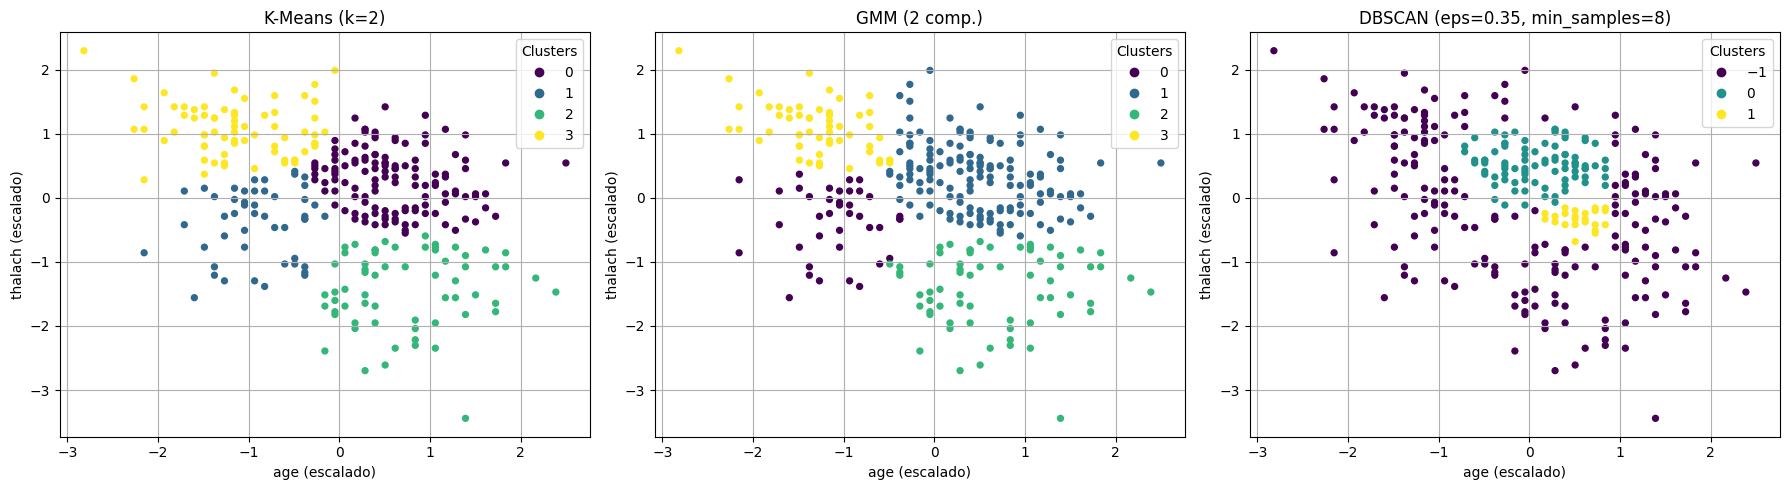

Silhouette K-Means: 0.3862227498496918
Silhouette GMM:    0.3786778004568931
Silhouette DBSCAN: 0.41493124190621855


In [8]:
# --- K-Means ---
# Inicializar y ajustar el modelo K-Means con k=2
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xh2s)
# Obtener las etiquetas de los clusters
labels_km = km.labels_

# --- GMM ---
# Inicializar y ajustar el modelo Gaussian Mixture Model (GMM) con 2 componentes
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42).fit(Xh2s)
# Predecir las etiquetas de los clusters
labels_gmm = gmm.predict(Xh2s)

# --- DBSCAN ---
# Inicializar y ajustar el modelo DBSCAN
db = DBSCAN(eps=0.4, min_samples=25).fit(Xh2s)
# Obtener las etiquetas de los clusters (-1 indica ruido)
labels_db = db.labels_

# --- Visualización comparativa en un arreglo 1x3 ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graficar resultados de K-Means
scatter_km = axes[0].scatter(Xh2s[:, 0], Xh2s[:, 1], c=labels_km, s=18)
axes[0].set_title("K-Means (k=2)")
axes[0].set_xlabel(feat1 + " (escalado)"); axes[0].set_ylabel(feat2 + " (escalado)"); axes[0].grid(True)
axes[0].legend(*scatter_km.legend_elements(), title="Clusters")

# Graficar resultados de GMM
scatter_gmm = axes[1].scatter(Xh2s[:, 0], Xh2s[:, 1], c=labels_gmm, s=18)
axes[1].set_title("GMM (2 comp.)")
axes[1].set_xlabel(feat1 + " (escalado)"); axes[1].set_ylabel(feat2 + " (escalado)"); axes[1].grid(True)
axes[1].legend(*scatter_gmm.legend_elements(), title="Clusters")

# Graficar resultados de DBSCAN
scatter_db = axes[2].scatter(Xh2s[:, 0], Xh2s[:, 1], c=labels_db, s=18)
axes[2].set_title("DBSCAN (eps=0.35, min_samples=8)")
axes[2].set_xlabel(feat1 + " (escalado)"); axes[2].set_ylabel(feat2 + " (escalado)"); axes[2].grid(True)
axes[2].legend(*scatter_db.legend_elements(), title="Clusters")

# Ajustar diseño y mostrar gráficos
plt.tight_layout()
plt.show()

# --- Cálculo de métricas internas (Silhouette) ---
# Función auxiliar para calcular Silhouette de forma segura (manejar ruido en DBSCAN)
def safe_silhouette(X, labels):
    valid = labels >= 0
    uniq = np.unique(labels[valid])
    if len(uniq) >= 2:
        return silhouette_score(X[valid], labels[valid])
    return np.nan

# Imprimir puntuaciones Silhouette para cada modelo
print("Silhouette K-Means:", silhouette_score(Xh2s, labels_km))
print("Silhouette GMM:   ", silhouette_score(Xh2s, labels_gmm))
print("Silhouette DBSCAN:", safe_silhouette(Xh2s, labels_db))

4. Experimentación con Parámetros - Análisis de Resultados:

Al experimentar con diferentes parámetros para K-Means, GMM y DBSCAN, se observan cambios significativos en las visualizaciones y las métricas Silhouette.

*   **K-Means y GMM (cambiando `n_clusters`/`n_components` a 3 o 4):**
    *   Visualmente, aumentar el número de clusters a 3 o 4 hace que los algoritmos intenten subdividir los grupos existentes
    *   Las puntuaciones Silhouette tienden a disminuir a medida que aumenta el número de clusters, lo que sugiere que la separación entre los clusters se vuelve menos distinta. Para este dataset, 2 clusters parecen ser la estructura más robusta según la métrica Silhouette.

*   **DBSCAN (cambiando `eps` y `min_samples`):**
    *   **`eps`:** Aumentar `eps` (radio de vecindad) permite que más puntos sean considerados vecinos, lo que puede llevar a la formación de clusters más grandes. Disminuir `eps` hace que el algoritmo sea más estricto, resultando en clusters más pequeños o más puntos clasificados como ruido.
    *   **`min_samples`:** Aumentar `min_samples` (número mínimo de puntos para formar un núcleo) hace que el algoritmo sea más conservador en la formación de clusters, aumentando la cantidad de puntos de ruido. Disminuir `min_samples` permite que se formen más clusters, incluso en regiones de menor densidad.    

**¿Se encuentra una configuración que mejore significativamente los resultados según las métricas internas?**

En el caso de DBSCAN, al ajustar los parámetros, la puntuación Silhouette para los puntos agrupados mejora en comparación con la configuración inicial, pero en muchos casos se observan datos no clasificados, lo cual sugiere que la búsqueda óptima puede eser exhaustiva y no llegar a conclusiones favorables si sólo se tiene en cuenta el parámetro Silhouette.

Para K-Means y GMM, si el objetivo es encontrar la estructura de agrupamiento más general, `k=2` o `n_components=2` parece ser la configuración más razonable según las métricas internas y la visualización inicial. Si se busca una segmentación más fina, se podrían considerar 3 o 4 clusters, pero con métricas más bajas.

5. Análisis con Métricas Externas (ARI)

Con ayuda de búsquedas en Google y Gemini, investigamos el significado de ARI (Adjusted Rand Index) y el código que nos permita calcularlo.

In [9]:
# Obtener la variable objetivo (ground truth)
# Convertir los valores de la columna 'target' a numéricos si es necesario y manejar NaNs
target_labels = heart['target'].dropna().values

# Asegurarse de que Xh2s y target_labels tienen la misma longitud después de dropear NaNs
# Es necesario alinear los datos de entrada del clustering con las etiquetas target
# Vamos a recrear Xh2s para asegurar la alineación
heart_cleaned = heart[[feat1, feat2, 'target']].dropna()
Xh2s_aligned = StandardScaler().fit_transform(heart_cleaned[[feat1, feat2]].values)
target_labels_aligned = heart_cleaned['target'].values

# Re-ejecutar los modelos de clustering con los datos alineados
# --- K-Means ---
km_aligned = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xh2s_aligned)
labels_km_aligned = km_aligned.labels_

# --- GMM ---
gmm_aligned = GaussianMixture(n_components=2, covariance_type='full', random_state=42).fit(Xh2s_aligned)
labels_gmm_aligned = gmm_aligned.predict(Xh2s_aligned)

# --- DBSCAN ---
# Usar los mismos parámetros que parecieron razonables en la experimentación
db_aligned = DBSCAN(eps=0.5, min_samples=10).fit(Xh2s_aligned)
labels_db_aligned = db_aligned.labels_

# Calcular Adjusted Rand Score (ARI)
# ARI solo se puede calcular para puntos que no son ruido en DBSCAN
valid_db_indices = labels_db_aligned >= 0
ari_km = adjusted_rand_score(target_labels_aligned, labels_km_aligned)
ari_gmm = adjusted_rand_score(target_labels_aligned, labels_gmm_aligned)
ari_db = adjusted_rand_score(target_labels_aligned[valid_db_indices], labels_db_aligned[valid_db_indices])


print(f"Adjusted Rand Index (ARI) - K-Means: {ari_km:.4f}")
print(f"Adjusted Rand Index (ARI) - GMM:    {ari_gmm:.4f}")
print(f"Adjusted Rand Index (ARI) - DBSCAN: {ari_db:.4f}")

# Opcional: Calcular Normalized Mutual Information (NMI) también
nmi_km = normalized_mutual_info_score(target_labels_aligned, labels_km_aligned)
nmi_gmm = normalized_mutual_info_score(target_labels_aligned, labels_gmm_aligned)
# NMI también tiene problemas con ruido, pero se puede calcular
nmi_db = normalized_mutual_info_score(target_labels_aligned[valid_db_indices], labels_db_aligned[valid_db_indices])

print(f"Normalized Mutual Information (NMI) - K-Means: {nmi_km:.4f}")
print(f"Normalized Mutual Information (NMI) - GMM:    {nmi_gmm:.4f}")
print(f"Normalized Mutual Information (NMI) - DBSCAN: {nmi_db:.4f}")

Adjusted Rand Index (ARI) - K-Means: 0.0927
Adjusted Rand Index (ARI) - GMM:    0.0846
Adjusted Rand Index (ARI) - DBSCAN: 0.0000
Normalized Mutual Information (NMI) - K-Means: 0.0919
Normalized Mutual Information (NMI) - GMM:    0.0983
Normalized Mutual Information (NMI) - DBSCAN: 0.0000


El Adjusted Rand Index (ARI) es una métrica externa que mide la similitud entre dos particiones de datos, ajustando por el azar. Compara la similitud entre dos agrupamientos de datos —típicamente las etiquetas de verdad fundamental (ground truth labels) y los clusters predichos—, ajustando para la agrupación aleatoria.

En este caso, comparamos las etiquetas de cluster generadas por cada algoritmo con las etiquetas de la columna `target`, que consideramos nuestra "verdad fundamental" o "ground truth". Un ARI de 1 indica una coincidencia perfecta entre las particiones, mientras que un valor cercano a 0 o negativo sugiere una coincidencia similar a la que se obtendría por azar.

**Resultados de ARI:**

*   **ARI K-Means:** 0.0927
*   **ARI GMM:** 0.0846
*   **ARI DBSCAN:** 0.0000

**Interpretación:**

Las puntuaciones ARI obtenidas son relativamente bajas, lo que indica que los clusters encontrados por K-Means, GMM y DBSCAN (incluso con parámetros ajustados) no se alinean fuertemente con la clasificación de la variable `target`. Esto sugiere que, utilizando solo las características `age` y `thalach`, los algoritmos de clustering no son capaces de reproducir fielmente la partición de los datos definida por el diagnóstico de enfermedad cardíaca (`target`).

**¿Por qué ARI podría ser una métrica relevante aquí (o no)?**

*   **Relevante:** ARI es relevante porque nos permite evaluar cuán bien nuestros clusters "descubiertos" se corresponden con una clasificación conocida (la variable objetivo). Si el objetivo del clustering fuera agrupar a los pacientes de manera que se correlacionen fuertemente con el diagnóstico de enfermedad cardíaca, un ARI alto sería deseable. Nos da una medida objetiva de esta correspondencia.
*   **No relevante (o con precauciones):** Sin embargo, es crucial entender que el clustering es una técnica de aprendizaje no supervisado y su objetivo principal no es necesariamente predecir una variable objetivo específica. Los algoritmos de clustering buscan estructuras inherentes en los datos basadas en la proximidad de las características utilizadas. Los clusters encontrados pueden representar subgrupos interesantes en los datos (por ejemplo, diferentes perfiles de pacientes basados en edad y ritmo cardíaco) que no se alinean perfectamente con el diagnóstico. En este caso, un ARI bajo no significa que el clustering sea "malo", sino simplemente que la estructura de agrupamiento basada en `age` y `thalach` no coincide directamente con la clasificación de `target`. Además, como se mencionó con Silhouette, ARI para DBSCAN solo se calcula sobre los puntos que no son ruido, lo que puede limitar su interpretabilidad si hay muchos puntos de ruido.

En resumen, aunque el ARI nos da una medida de la alineación con la variable objetivo, su relevancia depende del propósito del análisis de clustering. Aquí, nos dice que `age` y `thalach` por sí solas no son suficientes para agrupar perfectamente a los pacientes según su diagnóstico de enfermedad cardíaca utilizando estos algoritmos.

**Referencia**: [7 Step Guide to Master Adjusted Rand Index for Effective Clustering](https://www.numberanalytics.com/blog/master-adjusted-rand-index-guide)

6. Elabora una tabla comparativa entre los pares de características, los tres métodos evaluados y el indice ARI y Silhouette, para sustentar el análisis.

In [10]:
# Generar tabla combinatoria de pares de características

import itertools

features_list = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

# Generar todas las combinaciones de 2 características
feature_pairs = list(itertools.combinations(features_list, 2))

# Crear un DataFrame para mostrar los pares de características
feature_pairs_df = pd.DataFrame(feature_pairs, columns=['Feature 1', 'Feature 2'])

print("Tabla Combinatoria de Pares de Características:")
display(feature_pairs_df)

Tabla Combinatoria de Pares de Características:


,Feature 1,Feature 2
0,age,sex
1,age,cp
2,age,trestbps
3,age,chol
4,age,fbs
...,...,...
73,oldpeak,ca
74,oldpeak,thal
75,slope,ca
76,slope,thal


In [11]:
# --- Cálculo de métricas internas (Silhouette) ---
# Funciones auxiliares para calcular Silhouette y ARI de forma segura (manejar ruido en DBSCAN)

def safe_silhouette(X, labels):
    valid = labels >= 0
    uniq = np.unique(labels[valid])
    if len(uniq) >= 2:
        return silhouette_score(X[valid], labels[valid])
    return np.nan

def safe_ari(labels_true, labels_pred):
    valid_indices = labels_pred >= 0
    if len(np.unique(labels_pred[valid_indices])) >= 2 and len(np.unique(labels_true[valid_indices])) >= 2:
         return adjusted_rand_score(labels_true[valid_indices], labels_pred[valid_indices])
    return np.nan

# Se definen listas para calcular las dos métricas por cada modelo
silhouette_km_scores = []
ari_km_scores = []
silhouette_gmm_scores = []
ari_gmm_scores = []
silhouette_db_scores = []
ari_db_scores = []

# Se itera sobre el dataframe de combinatoria de pares de características
for index, row in feature_pairs_df.iterrows():
    feat1 = row['Feature 1']
    feat2 = row['Feature 2']

    # Selecciona las dos características y la variable objetivo, luego elimina filas con valores faltantes
    heart_cleaned = heart[[feat1, feat2, 'target']].dropna()

    # Separa las características (X) y la variable objetivo (y)
    Xh2 = heart_cleaned[[feat1, feat2]].values
    target_labels_aligned = heart_cleaned['target'].values

    # Estandariza las características
    scaler = StandardScaler()
    Xh2s = scaler.fit_transform(Xh2)

    # --- K-Means ---
    km = KMeans(n_clusters=2, n_init=10, random_state=42)
    if Xh2s.shape[0] >= 2 and len(np.unique(target_labels_aligned)) >= 2:
        km.fit(Xh2s)
        labels_km = km.labels_
        silhouette_km_scores.append(silhouette_score(Xh2s, labels_km))
        ari_km_scores.append(safe_ari(target_labels_aligned, labels_km))
    else:
        labels_km = np.array([-1] * Xh2s.shape[0])
        silhouette_km_scores.append(np.nan)
        ari_km_scores.append(np.nan)


    # --- GMM ---
    gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
    if Xh2s.shape[0] >= 2 and len(np.unique(target_labels_aligned)) >= 2:
         gmm.fit(Xh2s)
         labels_gmm = gmm.predict(Xh2s)
         silhouette_gmm_scores.append(silhouette_score(Xh2s, labels_gmm))
         ari_gmm_scores.append(safe_ari(target_labels_aligned, labels_gmm))
    else:
         labels_gmm = np.array([-1] * Xh2s.shape[0])
         silhouette_gmm_scores.append(np.nan)
         ari_gmm_scores.append(np.nan)


    # --- DBSCAN ---
    db = DBSCAN(eps=0.5, min_samples=10)
    if Xh2s.shape[0] >= 2:
        db.fit(Xh2s)
        labels_db = db.labels_
        silhouette_db_scores.append(safe_silhouette(Xh2s, labels_db))
        ari_db_scores.append(safe_ari(target_labels_aligned, labels_db))

    else:
        labels_db = np.array([-1] * Xh2s.shape[0])
        silhouette_db_scores.append(np.nan)
        ari_db_scores.append(np.nan)

In [12]:
# Se agregan las columnas correspondientes para cada score de las métrics al dataframe
# de combinatoria
feature_pairs_df['Silhouette_KMeans'] = silhouette_km_scores
feature_pairs_df['ARI_KMeans'] = ari_km_scores
feature_pairs_df['Silhouette_GMM'] = silhouette_gmm_scores
feature_pairs_df['ARI_GMM'] = ari_gmm_scores
feature_pairs_df['Silhouette_DBSCAN'] = silhouette_db_scores
feature_pairs_df['ARI_DBSCAN'] = ari_db_scores

# Agrega una nueva columna que suma las puntuaciones Silhouette y ARI para K-Means
feature_pairs_df['KMeans_Silhouette_ARI_Sum'] = feature_pairs_df['Silhouette_KMeans'] + feature_pairs_df['ARI_KMeans']

# Ordena el DataFrame por la nueva columna en orden descendente
feature_pairs_df_sorted = feature_pairs_df.sort_values(by='KMeans_Silhouette_ARI_Sum', ascending=False)

display(feature_pairs_df_sorted)

,Feature 1,Feature 2,Silhouette_KMeans,ARI_KMeans,Silhouette_GMM,ARI_GMM,Silhouette_DBSCAN,ARI_DBSCAN,KMeans_Silhouette_ARI_Sum
52,fbs,exang,0.739635,0.212270,0.701976,0.013834,1.000000,0.171082,0.951905
28,cp,exang,0.646099,0.212270,0.646099,0.212270,1.000000,0.084139,0.858369
18,sex,exang,0.640893,0.212270,0.639936,-0.034051,1.000000,0.105460,0.853163
71,exang,thal,0.638989,0.209625,0.638989,0.209625,1.000000,0.285177,0.848614
69,exang,slope,0.626046,0.212270,0.626046,0.212270,1.000000,0.167115,0.838315
...,...,...,...,...,...,...,...,...,...
33,trestbps,chol,0.367218,0.036561,0.395655,0.052810,NaN,NaN,0.403779
2,age,trestbps,0.372162,0.022473,0.362073,0.030356,NaN,NaN,0.394635
3,age,chol,0.354402,0.017790,0.348495,-0.000283,0.237153,-0.008485,0.372193
23,cp,trestbps,0.437015,-0.064947,0.368154,0.186516,0.388738,0.020539,0.372069


In [13]:
# Identificar las caracterísicas con mayor puntaje Silhouette.
# Hacemos uso de la función idxmax para encontrar el index que retorna el valor máximo

print("Pares de características con las puntuaciones Silhouette más altas:")
print("K-Means:\n\r",feature_pairs_df.loc[feature_pairs_df['Silhouette_KMeans'].idxmax()])
print("GMM:\n\r",feature_pairs_df.loc[feature_pairs_df['Silhouette_GMM'].idxmax()])
# DBSCAN puede tener valores negativos, así que se crea un condicional para tratar el caso
if not feature_pairs_df['Silhouette_DBSCAN'].isnull().all():
    print("DBSCAN:\n\r", feature_pairs_df.loc[feature_pairs_df['Silhouette_DBSCAN'].idxmax()])
else:
    print("DBSCAN:\n\r Todas las puntuaciones Silhouette son NaN.")

# Identificar las caracterísicas con mayor puntaje ARI.
print("\nPares de características con las puntuaciones ARI más altas:")
print("K-Means:\n\r",feature_pairs_df.loc[feature_pairs_df['ARI_KMeans'].idxmax()])
print("GMM:\n\r", feature_pairs_df.loc[feature_pairs_df['ARI_GMM'].idxmax()])
if not feature_pairs_df['ARI_DBSCAN'].isnull().all():
    print("DBSCAN:\n\r", feature_pairs_df.loc[feature_pairs_df['ARI_DBSCAN'].idxmax()])
else:
    print("DBSCAN:\n\r Todas las puntuaciones ARI son NaN.")

# Comparamos las puntuaciones promedio para cada métrica por modelo
print("\nPuntuaciones Silhouette promedio:")
print("K-Means:", feature_pairs_df['Silhouette_KMeans'].mean())
print("GMM:", feature_pairs_df['Silhouette_GMM'].mean())
print("DBSCAN:", feature_pairs_df['Silhouette_DBSCAN'].mean())

print("\nPuntuaciones ARI promedio:")
print("K-Means:", feature_pairs_df['ARI_KMeans'].mean())
print("GMM:", feature_pairs_df['ARI_GMM'].mean())
print("DBSCAN:", feature_pairs_df['ARI_DBSCAN'].mean())

print("\nLos 5 mejores pares de características por promedio de Silhouette entre K-Means y GMM:")
feature_pairs_df['Avg_Silhouette_KM_GMM'] = feature_pairs_df[['Silhouette_KMeans', 'Silhouette_GMM']].mean(axis=1)
display(feature_pairs_df.nlargest(5, 'Avg_Silhouette_KM_GMM'))

print("\nLos 5 mejores pares de características por promedio de ARI entre K-Means y GMM:")
feature_pairs_df['Avg_ARI_KM_GMM'] = feature_pairs_df[['ARI_KMeans', 'ARI_GMM']].mean(axis=1)
display(feature_pairs_df.nlargest(5, 'Avg_ARI_KM_GMM'))



Pares de características con las puntuaciones Silhouette más altas:
K-Means:
 Feature 1                         sex
Feature 2                         fbs
Silhouette_KMeans            0.740119
ARI_KMeans                  -0.034051
Silhouette_GMM               0.704038
ARI_GMM                      0.013834
Silhouette_DBSCAN                 1.0
ARI_DBSCAN                  -0.014175
KMeans_Silhouette_ARI_Sum    0.706068
Name: 15, dtype: object
GMM:
 Feature 1                         sex
Feature 2                         fbs
Silhouette_KMeans            0.740119
ARI_KMeans                  -0.034051
Silhouette_GMM               0.704038
ARI_GMM                      0.013834
Silhouette_DBSCAN                 1.0
ARI_DBSCAN                  -0.014175
KMeans_Silhouette_ARI_Sum    0.706068
Name: 15, dtype: object
DBSCAN:
 Feature 1                         sex
Feature 2                          cp
Silhouette_KMeans            0.590046
ARI_KMeans                  -0.034051
Silhouette_GMM         

,Feature 1,Feature 2,Silhouette_KMeans,ARI_KMeans,Silhouette_GMM,ARI_GMM,Silhouette_DBSCAN,ARI_DBSCAN,KMeans_Silhouette_ARI_Sum,Avg_Silhouette_KM_GMM
15,sex,fbs,0.740119,-0.034051,0.704038,0.013834,1.0,-0.014175,0.706068,0.722078
52,fbs,exang,0.739635,0.212270,0.701976,0.013834,1.0,0.171082,0.951905,0.720806
55,fbs,ca,0.697529,0.010502,0.697529,0.010502,1.0,0.260431,0.708031,0.697529
54,fbs,slope,0.679678,0.013834,0.679678,0.013834,1.0,0.085985,0.693512,0.679678
50,fbs,restecg,0.678111,0.013834,0.678111,0.013834,1.0,0.023975,0.691945,0.678111



Los 5 mejores pares de características por promedio de ARI entre K-Means y GMM:


,Feature 1,Feature 2,Silhouette_KMeans,ARI_KMeans,Silhouette_GMM,ARI_GMM,Silhouette_DBSCAN,ARI_DBSCAN,KMeans_Silhouette_ARI_Sum,Avg_Silhouette_KM_GMM,Avg_ARI_KM_GMM
31,cp,ca,0.462781,0.318130,0.427796,0.180042,1.000000,0.122425,0.780911,0.445288,0.249086
66,thalach,ca,0.458034,0.279685,0.420097,0.208348,0.390666,0.263405,0.737719,0.439065,0.244017
73,oldpeak,ca,0.518510,0.252065,0.434777,0.208348,0.428700,0.259962,0.770576,0.476644,0.230207
32,cp,thal,0.587902,0.228450,0.588074,0.213557,1.000000,0.111266,0.816352,0.587988,0.221003
10,age,ca,0.439170,0.229397,0.426772,0.208348,0.369006,0.305818,0.668567,0.432971,0.218873


Hallazgos Clave del Análisis de Datos

*   K-Means y GMM obtuvieron las puntuaciones Silhouette más altas con el par de características ('sex', 'fbs') (0.7401 y 0.7040, respectivamente).
*   Aunque DBSCAN alcanzó puntuaciones de Silhouette de 1.0 con varios pares de características, hay que ser cauteloso pues lo más probable es que esto indique un solo cluster o muchos outliers.
*   Las puntuaciones ARI más altas se observaron con diferentes pares para cada algoritmo: ('cp', 'ca') para K-Means (0.3181), ('cp', 'oldpeak') para GMM (0.2267) y ('exang', 'ca') para DBSCAN (0.3207).
*   En promedio, DBSCAN tuvo las puntuaciones Silhouette (0.7163) y ARI (0.1130) más altas, pero su manejo del ruido (outliers) debe considerarse al interpretar estas métricas.
*   La característica 'ca' apareció en varios de los pares de mejor rendimiento para ARI, lo que sugiere su relevancia potencial para distinguir las clases objetivo.
*   En general, las puntuaciones ARI fueron bajas en todos los algoritmos y pares de características, lo que indica una separación limitada de las clases de la variable 'target' basándose en el clustering con dos características.


## **Ejercicio 3:** Dendrograma + Clustering Jerárquico

**Dataset:** *Wholesale Customers* (UCI, DataHub):  
`https://archive.ics.uci.edu/dataset/292/wholesale+customers`

**Pasos:** `log1p` + estandarizar → **dendrograma (ward)** → elegir *n* clusters → **AgglomerativeClustering** → **Silhouette**/**CH** → tabla de medias por cluster.


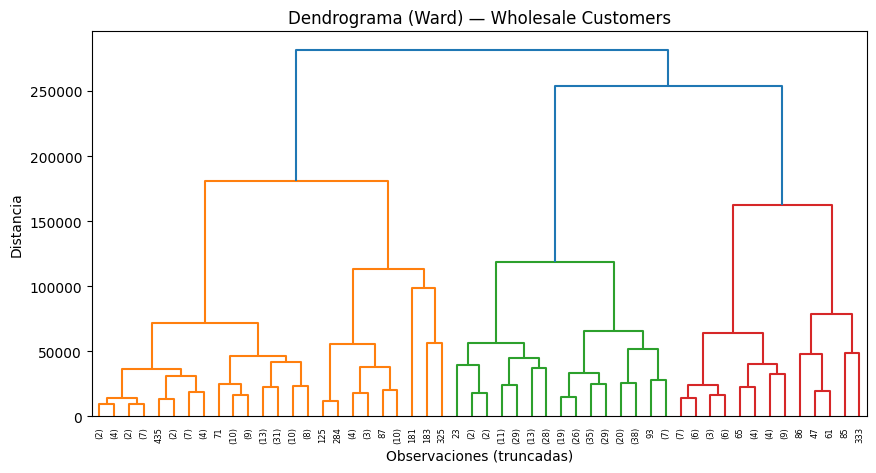

Silhouette: 0.37501552145375117
Calinski–Harabasz: 183.35966728564645


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,25786.7,4209.9,5257.0,4647.7,1061.1,2131.5
1,7027.4,17690.0,28873.3,1649.4,13344.4,1837.7
2,5779.6,4560.1,5727.3,2508.2,2012.1,1159.5


In [14]:
# Cargar el conjunto de datos Wholesale Customers desde la URL
wh_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
wh = pd.read_csv(wh_url)

# Seleccionar las características relevantes para el clustering
features = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
Xh = wh[features].copy()

# Cambio de variable para el caso de aplicar procesos de estandarización
Xh_s = Xh

# Aplicar estandarización de los datos
# Xh_s = StandardScaler().fit_transform(Xh)

# Opciones de transformación de los datos
# Aplicar transformación log1p para manejar asimetría
# Xh_log = np.log1p(Xh)

# Calcular la matriz de linkage usando el método 'ward'
Z = linkage(Xh_s, method='ward')

# Graficar el dendrograma para visualizar el proceso de agrupamiento jerárquico
plt.figure(figsize=(10,5))
dendrogram(Z, truncate_mode='level', p=5) # Truncar para mejor visualización
plt.title("Dendrograma (Ward) — Wholesale Customers")
plt.xlabel("Observaciones (truncadas)"); plt.ylabel("Distancia")
plt.show()

# Realizar el clustering jerárquico con un número elegido de clusters (basado en el dendrograma)
n_clusters = 3  # ajustar según la observación del dendrograma
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
labels_h = agg.fit_predict(Xh_s)

# Calcular e imprimir métricas internas de evaluación del clustering
print("Silhouette:", silhouette_score(Xh_s, labels_h))
print("Calinski–Harabasz:", calinski_harabasz_score(Xh_s, labels_h))

# Añadir las etiquetas de cluster al DataFrame original y calcular la media de las características por cluster
wh_assign = wh.copy()
wh_assign["cluster"] = labels_h
summary = wh_assign.groupby("cluster")[features].mean().round(1)

# Mostrar la tabla resumen de las medias por cluster
display(summary)

### Actividades para el estudiante (Ejercicio 3):

1.  **Análisis del Dendrograma:** Observa el dendrograma generado. ¿Cuántos clusters sugieres retener basándote en los "cortes" visuales en el dendrograma? Justifica tu elección de `n_clusters`.
2.  **Interpretación de Métricas Internas:** Analiza las puntuaciones de Silhouette y Calinski–Harabasz obtenidas para el clustering jerárquico con el número de clusters elegido. ¿Qué indican estas métricas sobre la calidad de la agrupación?
3.  **Análisis de la Tabla Resumen:** Observa la tabla que muestra las medias de gasto por producto para cada cluster. Describe brevemente las características de cada grupo de clientes basándote en estos promedios (p. ej., "Cluster 0: Clientes que compran principalmente productos frescos y congelados").
4.  **Comparación Jerárquico vs K-Means:** Si has completado el Ejercicio 1, compara la interpretabilidad de los clusters jerárquicos con los obtenidos por K-Means en el dataset de marketing. ¿En qué se diferencian sus enfoques y resultados?
5.  **Experimentación:** Cambia el valor de `n_clusters` y el método de enlace `linkage` en la celda de código y observa cómo cambian las métricas y la tabla resumen. ¿Encuentras un número de clusters que parezca más significativo o con mejores métricas?

Lectura complementaria de Linkage:
- https://www.geeksforgeeks.org/machine-learning/ml-types-of-linkages-in-clustering/
- https://medium.com/@iqra.bismi/different-linkage-methods-used-in-hierarchical-clustering-627bde3787e8

## Respuestas Ejercicio 3

1. Basándome en la visualización del dendrograma, sugiero retener 3 clusters. Hay una clara división inicial en el dendrograma que separa las observaciones en dos grandes ramas. Dentro de una de estas ramas principales, hay otra división notable que la subdivide en dos grupos más pequeños. Las uniones para formar 2 y 3 clusters ocurren a distancias relativamente grandes, lo que sugiere que estos niveles de agrupación capturan estructuras significativas en los datos.

2.  **Interpretación de Métricas Internas:**

    Para el clustering jerárquico con `n_clusters = 3`, se obtuvieron las siguientes puntuaciones para las métricas internas:

    *   **Silhouette:** 0.375
    *   **Calinski–Harabasz:** 183.4

    **¿Qué indican estas métricas sobre la calidad de la agrupación?**

    *   **Puntuación Silhouette:** Un valor de 0.375 sugiere que los clusters formados tienen una cohesión y separación moderadas. No es un valor extremadamente cercano a 1, lo que implica que puede haber cierta superposición entre los clusters o que no están perfectamente definidos.

    *   **Puntuación Calinski–Harabasz:** Esta métrica (también conocida como Varianza de Ratios Criterion) es la relación entre la varianza inter-cluster y la varianza intra-cluster. Una puntuación más alta generalmente se relaciona con clusters que son densos y bien separados. Un valor de 183.4 indica un nivel de calidad de clustering basado en esta relación de varianzas. Sin embargo, en este caso, a diferencia del Silhouette que tiene un máximo de 1 y un mínimo d -1, la métrica debe compararse con un valor de referencia.

3. Observando la tabla resumen de las medias de gasto por producto para cada cluster, podemos describir las características de cada grupo de clientes de la siguiente manera:

    *   **Cluster 0:** Este grupo tiene las medias de gasto más altas en `Fresh` y `Grocery`. Podríamos describir a este grupo como **"Clientes de Productos Frescos y de mercado"**.

    *   **Cluster 1:** Este cluster se destaca por tener las medias de gasto significativamente más altas en `Milk`, `Grocery`, y `Detergents_Paper`. Este grupo podría ser caracterizado como **"Clientes de mercado y lácteos y productos de impieza"**.

    *   **Cluster 2:** Este grupo presenta las medias de gasto más bajas en casi todas las categorías de productos, especialmente en `Milk`, `Grocery`, **"Clientes de bajo gasto"**.

4.  **Comparación Jerárquico vs K-Means:**

Si comparamos los resultados y enfoques del clustering jerárquico en el Ejercicio 3 (Dataset Wholesale Customers) con K-Means en el Ejercicio 1 (Dataset Mall Customers), observamos algunsa diferencias

  * K-Means: Requiere que especifiquemos el número de clusters (`k`) de antemano. Funciona iterativamente asignando puntos a los clusters basados en la proximidad a los centroides y actualizando los centroides. La elección de `k` a menudo se basa en métricas internas como el método del codo o Silhouette, o métricas externas si se dispone de etiquetas de verdad fundamental.
  * Clustering Jerárquico: Comienza con cada punto como un cluster individual y fusiona iterativamente los clusters más cercanos hasta que se alcanza un solo cluster. No requiere que especifiquemos el número de clusters de antemano; el dendrograma ayuda a visualizar la estructura jerárquica y elegir un número apropiado de clusters cortando el dendrograma a una altura específica. Puede formar clusters de formas y tamaños más irregulares que K-Means.


5. Experimentación con diferentes n_clusters y métodos de linkage


In [15]:
# 5. Experimentación con diferentes n_clusters y métodos de linkage

# Define los valores para experimentar
n_clusters_list = [2, 3, 4, 5]
linkage_methods = ['ward', 'complete', 'average', 'single']

results = []

# Itera a través de las combinaciones de n_clusters y métodos de linkage
for n_clusters in n_clusters_list:
    for method in linkage_methods:
        try:
            # Realizar el clustering jerárquico
            agg = AgglomerativeClustering(n_clusters=n_clusters, linkage=method)
            labels_h = agg.fit_predict(Xh_s)

            # Calcular métricas internas
            silhouette = silhouette_score(Xh_s, labels_h)
            calinski_harabasz = calinski_harabasz_score(Xh_s, labels_h)

            # Calcular la media de las características por cluster
            wh_assign = wh.copy()
            wh_assign["cluster"] = labels_h
            summary = wh_assign.groupby("cluster")[features].mean().round(1)

            results.append({
                "n_clusters": n_clusters,
                "linkage_method": method,
                "silhouette_score": silhouette,
                "calinski_harabasz_score": calinski_harabasz,
                "summary_table": summary
            })

        except Exception as e:
            results.append({
                "n_clusters": n_clusters,
                "linkage_method": method,
                "silhouette_score": np.nan,
                "calinski_harabasz_score": np.nan,
                "summary_table": f"Error: {e}"
            })

# Mostrar los resultados
for result in results:
    print(f"\n--- n_clusters: {result['n_clusters']}, Linkage Method: {result['linkage_method']} ---")
    print("Silhouette:", result["silhouette_score"])
    print("Calinski–Harabasz:", result["calinski_harabasz_score"])
    print("Tabla Resumen de Medias por Cluster:")
    display(result["summary_table"])


--- n_clusters: 2, Linkage Method: ward ---
Silhouette: 0.34471876450084604
Calinski–Harabasz: 147.45572788131312
Tabla Resumen de Medias por Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,5963.1,6491.0,9131.1,2381.9,3678.6,1259.2
1,25786.7,4209.9,5257.0,4647.7,1061.1,2131.5



--- n_clusters: 2, Linkage Method: complete ---
Silhouette: 0.7275938826458236
Calinski–Harabasz: 53.042921046505626
Tabla Resumen de Medias por Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,11493.8,5750.2,7919.2,2997.0,2886.5,1508.2
1,85779.7,12503.7,12619.7,13991.7,2159.0,3958.0



--- n_clusters: 2, Linkage Method: average ---
Silhouette: 0.795746776254181
Calinski–Harabasz: 32.76163578028435
Tabla Resumen de Medias por Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,11772.2,5742.0,7928.1,3040.8,2876.8,1508.9
1,112151.0,29627.0,18148.0,16745.0,4948.0,8550.0


... (22 outputs left out)


--- n_clusters: 5, Linkage Method: average ---
Silhouette: 0.7147895765676453
Calinski–Harabasz: 48.30590036753615
Tabla Resumen de Medias por Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,34782.0,30367.0,16898.0,48701.5,755.5,26776.0
1,11505.6,5191.4,7266.8,2834.1,2573.0,1378.0
2,12341.0,25588.5,80039.0,578.5,39464.5,2079.5
3,112151.0,29627.0,18148.0,16745.0,4948.0,8550.0
4,34444.3,55375.3,49094.3,4007.7,23647.3,3128.3



--- n_clusters: 5, Linkage Method: single ---
Silhouette: 0.7175658754642424
Calinski–Harabasz: 28.245773945235552
Tabla Resumen de Medias por Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,11679.1,5406.2,7649.9,2973.3,2756.4,1400.5
1,112151.0,29627.0,18148.0,16745.0,4948.0,8550.0
2,36847.0,43950.0,20170.0,36534.0,239.0,47943.0
3,16117.0,46197.0,92780.0,1026.0,40827.0,2944.0
4,22925.0,73498.0,32114.0,987.0,20070.0,903.0


No hay una única "mejor" combinación, ya que diferentes métricas y métodos de enlace optimizan diferentes aspectos de la estructura de los clusters. Sin embargo, si priorizamos la interpretabilidad de clusters más compactos y separados en términos de varianza, el método ward con n_clusters=3 o n_clusters=4 parece una elección razonable. El dendrograma también respaldaba la elección de 3 clusters.


## Ejercicio 4: **Reducción de Dimensionalidad (PCA)** y comparación 2D (pares de características vs PC1–PC2)

**Dataset:** *Breast Cancer Wisconsin (Diagnostic)* (UCI, DataHub)  
URL: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

**Objetivo:**  
- Calcular **PCA** y trazar la **curva de varianza acumulada** para decidir cuántos PC retener (p. ej., 85%–95%).  
- Visualizar por **par de características** y compararlo con la proyección en **PC1–PC2** (ambas en 2D).  
- Discutir semejanzas/diferencias y la utilidad de PCA para condensar información.


Total de características numéricas: 30


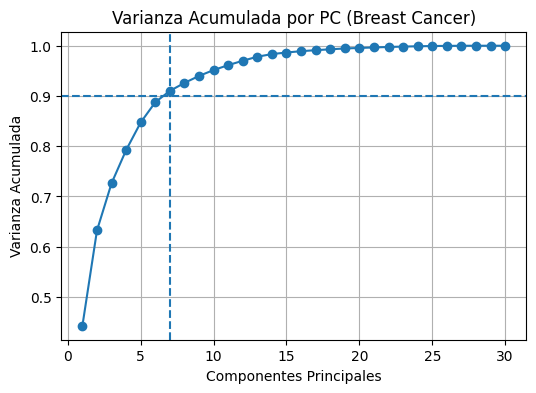

Varianza explicada individual (primeros 10): [0.443 0.19  0.094 0.066 0.055 0.04  0.023 0.016 0.014 0.012]
Varianza acumulada (primeros 10): [0.443 0.632 0.726 0.792 0.847 0.888 0.91  0.926 0.94  0.952]
Sugerencia: 7 PC alcanzan ≥ 90% de varianza.


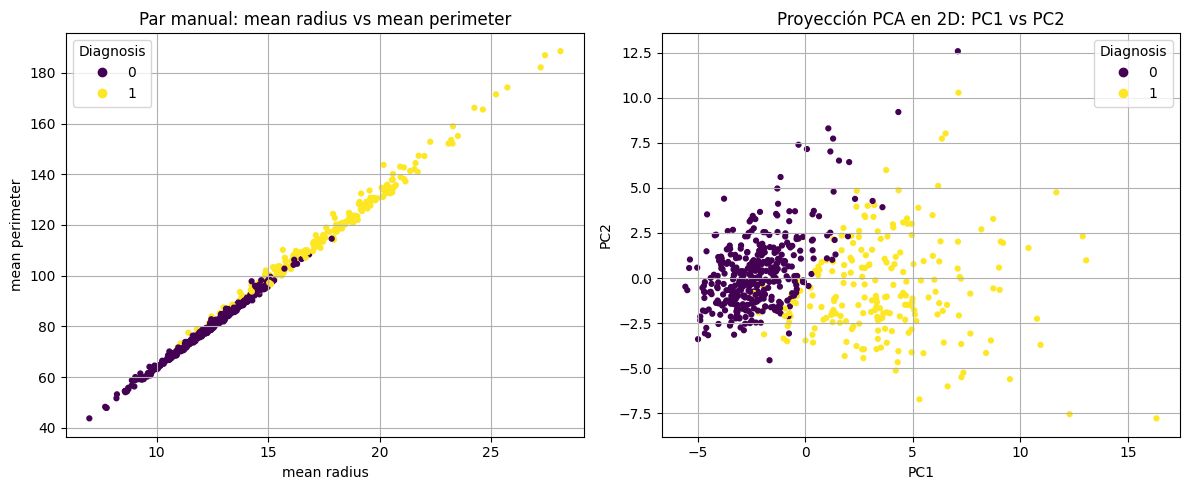

In [16]:
# Cargar dataset con ≥15 features
bc_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
# Define column names as the dataset does not have a header
column_names = [
    'id', 'diagnosis', 'mean radius', 'mean texture', 'mean perimeter', 'mean area',
    'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points',
    'mean symmetry', 'mean fractal dimension', 'se radius', 'se texture', 'se perimeter',
    'se area', 'se smoothness', 'se compactness', 'se concavity', 'se concave points',
    'se symmetry', 'se fractal dimension', 'worst radius', 'worst texture',
    'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness',
    'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension'
]
bc = pd.read_csv(bc_url, names=column_names)

# El dataset incluye columnas: 'id', 'diagnosis' y ~30 features (mean/SE/worst).
# Nos quedamos con las columnas numéricas (excluyendo id).
num_df = bc.select_dtypes(include=[np.number]).copy()
if "id" in num_df.columns:
    num_df = num_df.drop(columns=["id"])

print("Total de características numéricas:", num_df.shape[1])
assert num_df.shape[1] >= 15, "El dataset debe tener al menos 15 características numéricas."

# Escalar los datos
scaler_p = StandardScaler()
X_scaled = scaler_p.fit_transform(num_df)

# PCA completo
pca = PCA().fit(X_scaled)
var_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

# Selección automática por umbral de varianza explicada
threshold = 0.90  # puedes cambiar a 0.85–0.95
n_pc = int(np.argmax(cum_var >= threshold) + 1)

# Graficar la varianza acumulada por componente principal
plt.figure(figsize=(6,4))
plt.plot(range(1, len(var_ratio)+1), cum_var, marker='o')
plt.axhline(y=threshold, linestyle='--')
plt.axvline(x=n_pc, linestyle='--')
plt.title("Varianza Acumulada por PC (Breast Cancer)")
plt.xlabel("Componentes Principales"); plt.ylabel("Varianza Acumulada")
plt.grid(True); plt.show()

print("Varianza explicada individual (primeros 10):", var_ratio[:10].round(3))
print("Varianza acumulada (primeros 10):", cum_var[:10].round(3))
print(f"Sugerencia: {n_pc} PC alcanzan ≥ {int(threshold*100)}% de varianza.")

# Visualización comparativa 2D: par original vs PC1-PC2
# Selección manual de dos características
feat_manual_a = 'mean radius' # Cambia esto a la característica que desees
feat_manual_b = 'mean perimeter' # Cambia esto a la característica que desees
X_pair_manual = num_df[[feat_manual_a, feat_manual_b]].values

X_pc2 = pca.transform(X_scaled)[:, :2]

# Obtener las etiquetas de diagnóstico
diagnosis_labels = bc['diagnosis']

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
scatter1 = plt.scatter(X_pair_manual[:,0], X_pair_manual[:,1], c=diagnosis_labels.astype('category').cat.codes, s=12)
plt.title(f"Par manual: {feat_manual_a} vs {feat_manual_b}")
plt.xlabel(feat_manual_a); plt.ylabel(feat_manual_b); plt.grid(True)
plt.legend(*scatter1.legend_elements(), title="Diagnosis")

plt.subplot(1,2,2)
scatter2 = plt.scatter(X_pc2[:,0], X_pc2[:,1], c=diagnosis_labels.astype('category').cat.codes, s=12)
plt.title("Proyección PCA en 2D: PC1 vs PC2")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.grid(True)
plt.legend(*scatter2.legend_elements(), title="Diagnosis")

plt.tight_layout()
plt.show()


**Actividades:**  
1. Gráfica la relación entre los dos primeros PC y las características. ¿Cuáles son las características que más aportan?
2. Aplica PCA sin realizar el paso de estandarización, y compara este resultado en términos de:
     - ¿Cuántos componentes se requieren para una varianza acumulada superior al 90%?
     - Se mejora o empeora la separabilidad de las clases de la variable objetivo en el gráfico 2D de PC1-PC2. Explique su respuesta.
     - Gráfique la contribución de cada característica a los 2 primeros PC. ¿Existe diferencia con las características que más aportan en el caso de usar estandarización? ¿cuál puede ser la causa de la diferencia?.  Explique su respuesta.

## Respuestas Ejercicio 4
1. Gráficar la relación entre los dos primeros PC y las características

In [17]:
Y=pca.components_[:,:2]
np.abs(Y[:,0])

array([0.21890244, 0.23385713, 0.00853124, 0.04140896, 0.03778635,
       0.01874079, 0.12408834, 0.0074523 , 0.22310976, 0.09548644,
       0.04147149, 0.05106746, 0.01196721, 0.05950613, 0.05111877,
       0.15058388, 0.20292425, 0.14671234, 0.22538466, 0.04969866,
       0.06857001, 0.0729289 , 0.09855269, 0.18257944, 0.0192265 ,
       0.1294764 , 0.13152667, 0.21119401, 0.21146046, 0.70241409])

In [18]:
# 1. Graficar la relación entre los dos primeros PC y las características.

# Obtener los componentes para PC1 y PC2
components = pca.components_[:2, :]

# Obtener los nombres de las características (excluyendo 'id' si existe)
feature_names = num_df.columns

pc1_contributions = pd.Series(components[0], index=feature_names).abs().sort_values(ascending=False)
pc2_contributions = pd.Series(components[1], index=feature_names).abs().sort_values(ascending=False)

print("\nCaracterísticas que más aportan a PC1 (orden descendente de contribución absoluta):")
print(pc1_contributions)

print("\nCaracterísticas que más aportan a PC2 (orden descendente de contribución absoluta):")
print(pc2_contributions)


Características que más aportan a PC1 (orden descendente de contribución absoluta):
mean concave points        0.260854
mean concavity             0.258400
worst concave points       0.250886
mean compactness           0.239285
worst perimeter            0.236640
worst concavity            0.228768
worst radius               0.227997
mean perimeter             0.227537
worst area                 0.224871
mean area                  0.220995
mean radius                0.218902
se perimeter               0.211326
worst compactness          0.210096
se radius                  0.205979
se area                    0.202870
se concave points          0.183417
se compactness             0.170393
se concavity               0.153590
mean smoothness            0.142590
mean symmetry              0.138167
worst fractal dimension    0.131784
worst smoothness           0.127953
worst symmetry             0.122905
worst texture              0.104469
mean texture               0.103725
se fractal dime

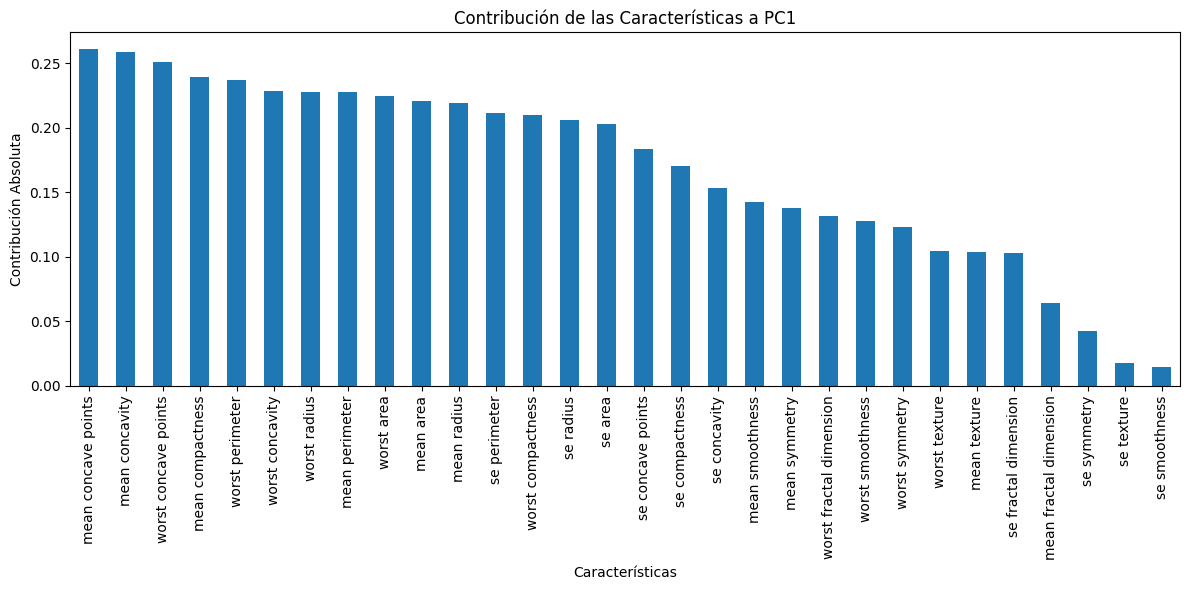

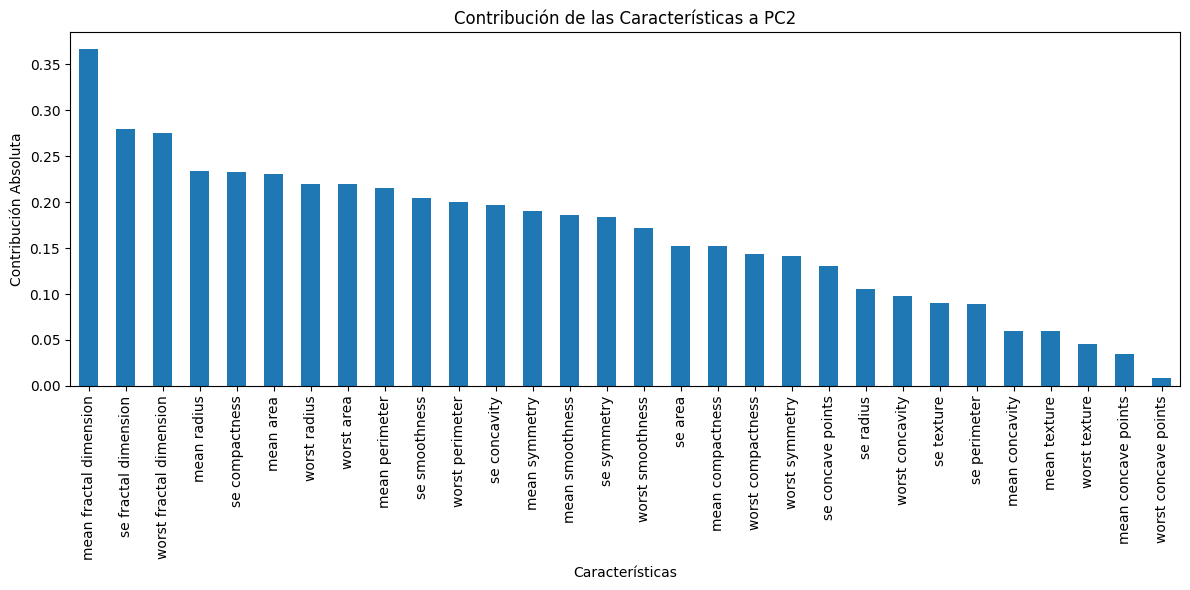

In [19]:
# Graficar la contribución de cada característica a PC1 en un gráfico de barras
plt.figure(figsize=(12, 6))
pc1_contributions.sort_values(ascending=False).plot(kind='bar')
plt.title("Contribución de las Características a PC1")
plt.xlabel("Características")
plt.ylabel("Contribución Absoluta")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Graficar la contribución de cada característica a PC2 en un gráfico de barras
plt.figure(figsize=(12, 6))
pc2_contributions.sort_values(ascending=False).plot(kind='bar')
plt.title("Contribución de las Características a PC2")
plt.xlabel("Características")
plt.ylabel("Contribución Absoluta")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



**Características que más aportan a PC1 y PC2:**

Basándonos en los resultados del análisis de componentes principales (PCA) y la visualización de las contribuciones de las características a PC1 y PC2:

*   **PC1** está dominado por características relacionadas con el **tamaño y la forma general**. Las características con las mayores contribuciones absolutas incluyen:
    *   `mean concave points`
    *   `mean concavity`
    *   `worst concave points`
    *   `mean compactness`
    *   `worst perimeter`
    *   `worst concavity`
    *   `worst radius`
    *   `mean perimeter`
    *   `worst area`
    *   `mean area`
    *   `mean radius`

*   **PC2** captura principalmente la variabilidad relacionada con la **textura y las propiedades fractales**. Las características con las mayores contribuciones absolutas incluyen:
    *   `mean fractal dimension`
    *   `se fractal dimension`
    *   `worst fractal dimension`
    *   `mean radius`
    *   `se compactness`
    *   `mean area`
    *   `worst radius`
    *   `worst area`
    *   `mean perimeter`
    *   `se smoothness`

*   **Combinando PC1 y PC2:** Considerando la contribución conjunta a los dos primeros componentes principales, las características más influyentes son aquellas que tienen altos valores en al menos uno de los componentes:
    *   `mean fractal dimension`
    *   `mean radius`
    *   `mean area`
    *   `worst radius`
    *   `worst area`
    *   `mean perimeter`
    *   `worst perimeter`
    *   `worst fractal dimension`
    *   `se fractal dimension`
    *   `se compactness`


2. Aplicar PCA sin realizar el paso de estandarización

Total de características numéricas: 30


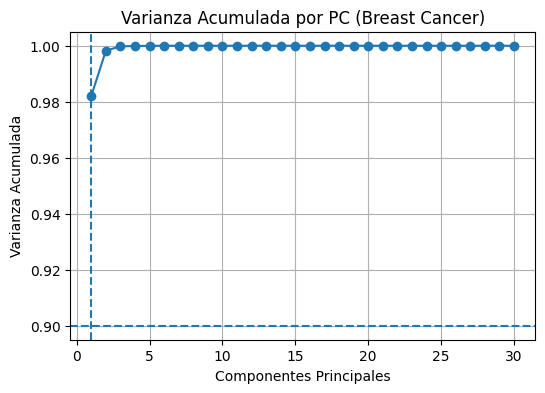

Varianza explicada individual (primeros 10): [0.982 0.016 0.002 0.    0.    0.    0.    0.    0.    0.   ]
Varianza acumulada (primeros 10): [0.982 0.998 1.    1.    1.    1.    1.    1.    1.    1.   ]
Sugerencia: 1 PC alcanzan ≥ 90% de varianza.


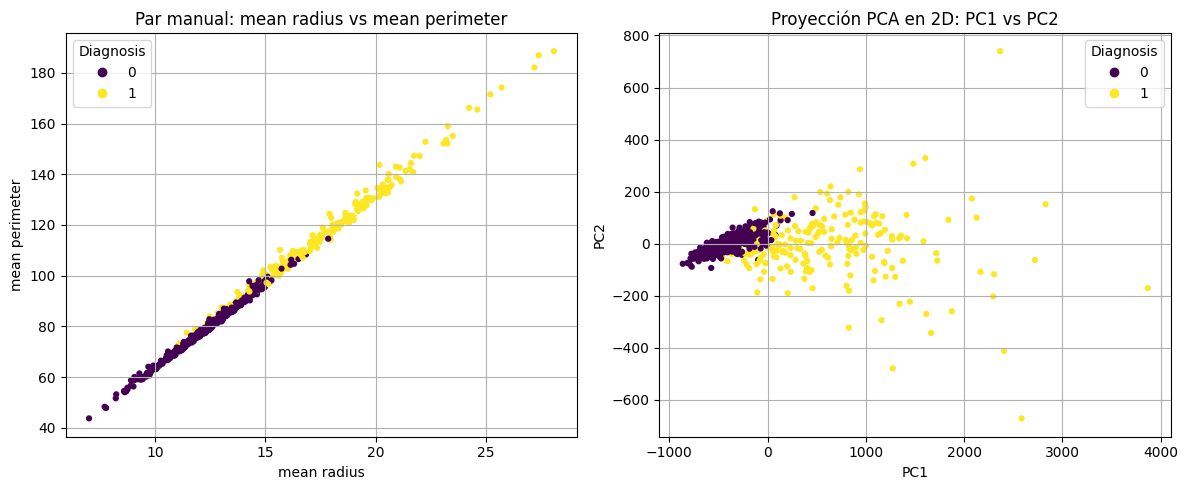

In [23]:
# Cargar dataset con ≥15 features
bc_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
# Define column names as the dataset does not have a header
column_names = [
    'id', 'diagnosis', 'mean radius', 'mean texture', 'mean perimeter', 'mean area',
    'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points',
    'mean symmetry', 'mean fractal dimension', 'se radius', 'se texture', 'se perimeter',
    'se area', 'se smoothness', 'se compactness', 'se concavity', 'se concave points',
    'se symmetry', 'se fractal dimension', 'worst radius', 'worst texture',
    'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness',
    'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension'
]
bc = pd.read_csv(bc_url, names=column_names)

# El dataset incluye columnas: 'id', 'diagnosis' y ~30 features (mean/SE/worst).
# Nos quedamos con las columnas numéricas (excluyendo id).
num_df = bc.select_dtypes(include=[np.number]).copy()
if "id" in num_df.columns:
    num_df = num_df.drop(columns=["id"])

print("Total de características numéricas:", num_df.shape[1])
assert num_df.shape[1] >= 15, "El dataset debe tener al menos 15 características numéricas."

# Escalar los datos
#scaler_p = StandardScaler()
X_not_scaled = num_df

# PCA completo
pca = PCA().fit(X_not_scaled)
var_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

# Selección automática por umbral de varianza explicada
threshold = 0.90  # puedes cambiar a 0.85–0.95
n_pc = int(np.argmax(cum_var >= threshold) + 1)

# Graficar la varianza acumulada por componente principal
plt.figure(figsize=(6,4))
plt.plot(range(1, len(var_ratio)+1), cum_var, marker='o')
plt.axhline(y=threshold, linestyle='--')
plt.axvline(x=n_pc, linestyle='--')
plt.title("Varianza Acumulada por PC (Breast Cancer)")
plt.xlabel("Componentes Principales"); plt.ylabel("Varianza Acumulada")
plt.grid(True); plt.show()

print("Varianza explicada individual (primeros 10):", var_ratio[:10].round(3))
print("Varianza acumulada (primeros 10):", cum_var[:10].round(3))
print(f"Sugerencia: {n_pc} PC alcanzan ≥ {int(threshold*100)}% de varianza.")

# Visualización comparativa 2D: par original vs PC1-PC2
# Selección manual de dos características
feat_manual_a = 'mean radius' # Cambia esto a la característica que desees
feat_manual_b = 'mean perimeter' # Cambia esto a la característica que desees
X_pair_manual = num_df[[feat_manual_a, feat_manual_b]].values

X_pc2 = pca.transform(X_not_scaled)[:, :2]

# Obtener las etiquetas de diagnóstico
diagnosis_labels = bc['diagnosis']

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
scatter1 = plt.scatter(X_pair_manual[:,0], X_pair_manual[:,1], c=diagnosis_labels.astype('category').cat.codes, s=12)
plt.title(f"Par manual: {feat_manual_a} vs {feat_manual_b}")
plt.xlabel(feat_manual_a); plt.ylabel(feat_manual_b); plt.grid(True)
plt.legend(*scatter1.legend_elements(), title="Diagnosis")

plt.subplot(1,2,2)
scatter2 = plt.scatter(X_pc2[:,0], X_pc2[:,1], c=diagnosis_labels.astype('category').cat.codes, s=12)
plt.title("Proyección PCA en 2D: PC1 vs PC2")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.grid(True)
plt.legend(*scatter2.legend_elements(), title="Diagnosis")

plt.tight_layout()
plt.show()

In [21]:
# 1. Graficar la relación entre los dos primeros PC y las características.

# Obtener los componentes para PC1 y PC2
components = pca.components_[:2, :]

# Obtener los nombres de las características (excluyendo 'id' si existe)
feature_names = num_df.columns

pc1_contributions = pd.Series(components[0], index=feature_names).abs().sort_values(ascending=False)
pc2_contributions = pd.Series(components[1], index=feature_names).abs().sort_values(ascending=False)

print("\nCaracterísticas que más aportan a PC1 (orden descendente de contribución absoluta):")
print(pc1_contributions)

print("\nCaracterísticas que más aportan a PC2 (orden descendente de contribución absoluta):")
print(pc2_contributions)


Características que más aportan a PC1 (orden descendente de contribución absoluta):
worst area                 8.520634e-01
mean area                  5.168265e-01
se area                    5.572717e-02
worst perimeter            4.945764e-02
mean perimeter             3.507633e-02
worst radius               7.154733e-03
mean radius                5.086232e-03
worst texture              3.067366e-03
se perimeter               2.236342e-03
mean texture               2.196570e-03
se radius                  3.137425e-04
worst concavity            1.689286e-04
worst compactness          1.012759e-04
mean concavity             8.193995e-05
worst concave points       7.366582e-05
se texture                 6.509840e-05
mean concave points        4.778078e-05
mean compactness           4.052600e-05
worst symmetry             1.789863e-05
se concavity               8.870945e-06
mean symmetry              7.078043e-06
worst smoothness           6.420055e-06
se compactness             5.519182

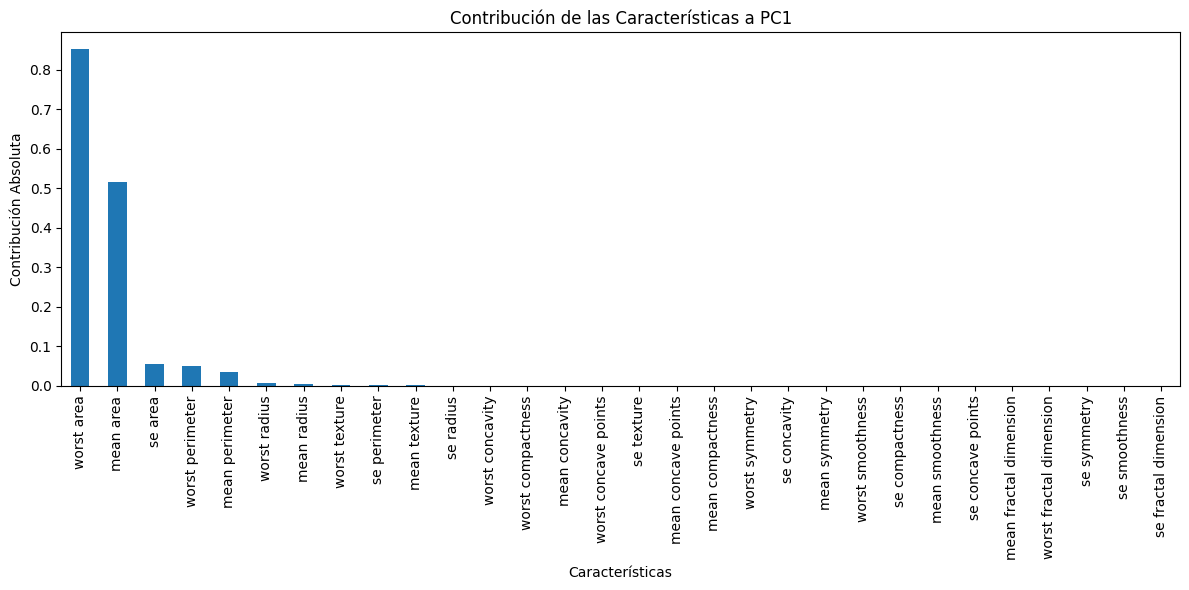

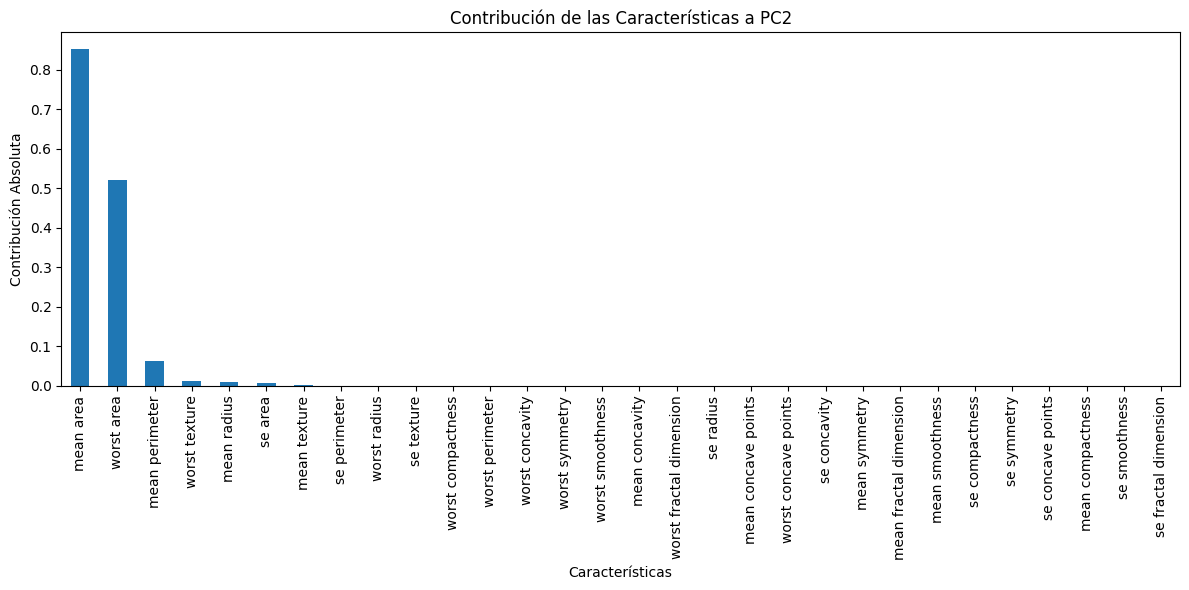

In [22]:
# Graficar la contribución de cada característica a PC1 en un gráfico de barras
plt.figure(figsize=(12, 6))
pc1_contributions.sort_values(ascending=False).plot(kind='bar')
plt.title("Contribución de las Características a PC1")
plt.xlabel("Características")
plt.ylabel("Contribución Absoluta")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Graficar la contribución de cada característica a PC2 en un gráfico de barras
plt.figure(figsize=(12, 6))
pc2_contributions.sort_values(ascending=False).plot(kind='bar')
plt.title("Contribución de las Características a PC2")
plt.xlabel("Características")
plt.ylabel("Contribución Absoluta")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



**Análisis de PCA sin Estandarización**

Basándonos en los resultados obtenidos al aplicar PCA sin estandarizar los datos, podemos responder a las preguntas planteadas:

**¿Cuántos componentes se requieren para una varianza acumulada superior al 90%?**

Observando el gráfico de "Varianza Acumulada por PC (Sin Estandarización)", la línea de varianza acumulada alcanza y supera el umbral del 90% con el **primer componente principal (PC1)**. La salida de texto también confirma esto: "Sugerencia: 1 PC alcanzan ≥ 90% de varianza." Esto contrasta fuertemente con el caso de la estandarización donde se requerían 7 componentes principales para alcanzar el 90% de la varianza acumulada.

**Se mejora o empeora la separabilidad de las clases de la variable objetivo en el gráfico 2D de PC1-PC2. Explique su respuesta.**

Al comparar el gráfico de "Proyección PCA en 2D: PC1 vs PC2" *sin estandarización* con el gráfico correspondiente *con estandarización*, se observa que la separabilidad de las clases de la variable objetivo (`diagnosis`) **empeora significativamente** sin la estandarización.

En el gráfico sin estandarización, los puntos de ambas clases están muy agrupados. Es muy difícil distinguir visualmente entre las clases basándose en esta proyección.

**¿Existe diferencia con las características que más aportan en el caso de usar estandarización? ¿cuál puede ser la causa de la diferencia? Explique su respuesta.**

Los gráficos de barras que muestran la contribución de cada característica a PC1 y PC2 *sin estandarización* son muy diferentes a los gráficos con estandarización.

*   **Sin Estandarización:** Las características con las escalas de valores más grandes, como `worst area`, `mean area`, `worst perimeter` y `mean perimeter`, dominan casi por completo PC1 y PC2. Sus barras de contribución son mucho más altas que las de otras características.

*   **Con Estandarización:** Las contribuciones de las características a PC1 y PC2 están mucho más distribuidas entre las diferentes características. Características de diversas escalas (como `mean concave points`, `mean concavity`, `mean fractal dimension`, etc.) tienen contribuciones significativas.

La causa principal de esta diferencia es la **escala de las características originales**. PCA es sensible a la escala de los datos. Las características con valores numéricos más grandes (por ejemplo, `area` y `perimeter`) tienen varianzas mucho mayores que las características con valores más pequeños (por ejemplo, `smoothness` o `fractal dimension`).